# 4.4 Simulasi IRIO Shock Pariwisata Bali

**Tujuan penelitian 2.** Membangun model simulasi *spatial spillover effects* berbasis Interregional Input–Output (IRIO) Network untuk menganalisis penyebaran shock sektor pariwisata antarsektor dan antarwilayah melalui struktur jaringan ekonomi.

Notebook ini melanjutkan `Shock_Constructor_Bali`, yang menghasilkan vektor perubahan permintaan akhir $\Delta f$. Seluruh proses disusun berurutan dan tiap bagian sepadan dengan satu subbab.

| Bagian | Isi | Pertanyaan yang dijawab |
|---|---|---|
| 0 | Persiapan | – |
| 1 | Tabel IRIO dan matriks Leontief | Apakah sistem input–output layak disimulasikan? |
| 2 | Struktur keterkaitan sektor Bali | Sektor mana yang paling kuat menarik dan mendorong sektor lain, dan seberapa besar kebocorannya ke provinsi lain? |
| 3 | Vektor shock | Berapa besar shock yang diinjeksikan, dan apakah masuk akal? |
| 4 | Simulasi Leontief | Berapa total penurunan output? |
| 5 | Dekomposisi dampak | Berapa bagian yang tertahan di Bali, kembali ke Bali, dan bocor ke luar Bali? |
| 6 | Sebaran dampak | Provinsi dan sektor mana yang paling terdampak? |
| 7 | Jaringan spillover | Lewat jalur perdagangan mana dampak menyebar? |
| 8 | Validasi | Apakah seluruh identitas dan syarat model terpenuhi? |
| 9 | Ekspor | Berkas masukan untuk Tujuan 3 (Moran's I dan LISA) |

```
Tabel IRIO (A, FD)        delta_f  (Shock_Constructor_Bali)
        |                        |
  L = (I - A)^-1                 |
        |                        |
  x = L . FD  ->  Z = A . diag(x)|
        |                        |
  Bagian 2: BL, FL, multiplier   |
        +-----------+------------+
                    |
          delta_x = L . delta_f          (Bagian 4)
                    |
   dekomposisi -> sebaran -> jaringan    (Bagian 5-7)
                    |
        validasi -> ekspor ke Tujuan 3   (Bagian 8-9)
```

**Satuan.** Seluruh nilai dalam tabel IRIO dalam juta rupiah. Tabel dan gambar menampilkan triliun rupiah (÷10⁶) atau miliar rupiah (÷10³). Dampak bertanda negatif berarti penurunan output. Pada gambar, besaran ditampilkan sebagai nilai absolut dengan label *penurunan output*.

---
## Bagian 0 — Persiapan


In [ ]:
import subprocess, sys
for pkg in ['openpyxl', 'geopandas', 'mapclassify', 'adjustText', 'networkx']:
    subprocess.run([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

import os, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import FancyArrowPatch, Patch
from matplotlib.lines import Line2D
import geopandas as gpd
import requests
from adjustText import adjust_text
from scipy import stats
from IPython.display import display
warnings.filterwarnings('ignore')

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/[01] Tugas-Atikah-STIS/[01] Skripsi Atikah/Data/'
except ImportError:
    BASE = os.environ.get('SKRIPSI_DATA', './Data/')

IN_DIR  = BASE
OUT_DIR = BASE
CSV_OUT_DIR  = OUT_DIR + 'csv_output/'
NPY_OUT_DIR  = OUT_DIR + 'npy_output/'
XLSX_OUT_DIR = OUT_DIR + 'xlsx_output/'
FIG_DIR      = OUT_DIR + 'figur/'
for d in [CSV_OUT_DIR, NPY_OUT_DIR, XLSX_OUT_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

F_IRIO   = IN_DIR + '01. Data_IRIO_17_Siap.xlsx'
F_DELTAF = IN_DIR + '07. delta_f.npy'
F_DETAIL = IN_DIR + '06. delta_f_detail.csv'

for f in [F_IRIO, F_DELTAF, F_DETAIL]:
    assert os.path.exists(f), f'Tidak ditemukan: {f}'
    print('OK :', os.path.basename(f))

Mounted at /content/drive
OK : 01. Data_IRIO_17_Siap.xlsx
OK : 07. delta_f.npy
OK : 06. delta_f_detail.csv


### 0.2 Gaya gambar dan fungsi bantu



In [ ]:
# SERTAKAN_JUDUL = True
SUMBER_IRIO    = 'Tabel IRIO Indonesia 2016 (BPS) dimutakhirkan ke 2025, diolah.'

SERTAKAN_JUDUL  = False   # judul ditulis di Word
SERTAKAN_SUMBER = False   # sumber dan catatan ditulis di Word

MM    = 1 / 25.4
LEBAR = 160 * MM

plt.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 8,
    'axes.titlesize': 8.5, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelsize': 8, 'xtick.labelsize': 7, 'ytick.labelsize': 7, 'legend.fontsize': 7,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6,
    'legend.frameon': False, 'figure.dpi': 130,
    'savefig.dpi': 300, 'savefig.bbox': 'tight', 'savefig.pad_inches': 0.08, 'pdf.fonttype': 42,
})

# Palet konsisten di seluruh gambar
C_BALI     = '#8C1D18'   # Bali, efek langsung
C_INTRA    = '#E08E45'   # efek tidak langsung intraregional
C_FEEDBACK = '#6A51A3'   # efek umpan balik
C_SPILL    = '#0072B2'   # spillover ke provinsi lain
C_ABU      = '#BDBDBD'
C_TEKS     = '#333333'


def fmt(x, d=2):
    # Format angka Indonesia: 12.345,67
    return f'{x:,.{d}f}'.replace(',', '#').replace('.', ',').replace('#', '.')


def _desimal(v):
    return 0 if v == 0 or abs(v) >= 1 else max(0, -int(np.floor(np.log10(abs(v)))))

def format_sumbu(fig):
    # Ganti label angka bawaan matplotlib (titik desimal) menjadi format Indonesia
    for ax in fig.axes:
        for sumbu in (ax.xaxis, ax.yaxis):
            f = sumbu.get_major_formatter()
            if sumbu.get_scale() == 'log' and isinstance(f, mpl.ticker.LogFormatter):
                sumbu.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p: fmt(v, _desimal(v))))
                sumbu.set_minor_formatter(mpl.ticker.NullFormatter())
            elif isinstance(f, mpl.ticker.ScalarFormatter):
                langkah = np.diff(sumbu.get_majorticklocs())
                d = _desimal(langkah[0]) if len(langkah) else 0
                sumbu.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, p, d=d: fmt(v, d).replace('-', '−')))


DAFTAR_GAMBAR = []

# def simpan(fig, kode, judul, sumber=SUMBER_IRIO, catatan=None):
#     # Tambahkan judul dan sumber, simpan PNG + PDF, catat ke DAFTAR_GAMBAR
#     format_sumbu(fig)
#     if SERTAKAN_JUDUL:
#         fig.suptitle(judul, x=0.01, ha='left', fontsize=9.5, fontweight='bold')
#     teks = f'Sumber: {sumber}' + (f'\nCatatan: {catatan}' if catatan else '')
#     fig.text(0.01, -0.005, teks, ha='left', va='top', fontsize=6.6, color='#555555',
#              transform=fig.transFigure)
#     for ext in ('png', 'pdf'):
#         fig.savefig(f'{FIG_DIR}{kode}.{ext}')
#     plt.show()
#     DAFTAR_GAMBAR.append({'No': len(DAFTAR_GAMBAR) + 1, 'Berkas': kode, 'Judul': judul,
#                           'Sumber': sumber, 'Catatan': catatan or ''})
#     print(f'Gambar {len(DAFTAR_GAMBAR)} tersimpan -> figur/{kode}.png | .pdf')

def simpan(fig, kode, judul, sumber=SUMBER_IRIO, catatan=None):
    # Tambahkan judul dan sumber (opsional), simpan PNG + PDF, catat ke DAFTAR_GAMBAR
    format_sumbu(fig)
    if SERTAKAN_JUDUL:
        fig.suptitle(judul, x=0.01, ha='left', fontsize=9.5, fontweight='bold')
    if SERTAKAN_SUMBER:
        teks = f'Sumber: {sumber}' + (f'\nCatatan: {catatan}' if catatan else '')
        fig.text(0.01, -0.005, teks, ha='left', va='top', fontsize=6.6, color='#555555',
                 transform=fig.transFigure)
    for ext in ('png', 'pdf'):
        fig.savefig(f'{FIG_DIR}{kode}.{ext}')
    plt.show()
    DAFTAR_GAMBAR.append({'No': len(DAFTAR_GAMBAR) + 1, 'Berkas': kode, 'Judul': judul,
                          'Sumber': sumber, 'Catatan': catatan or ''})
    print(f'Gambar {len(DAFTAR_GAMBAR)} tersimpan -> figur/{kode}.png | .pdf')


def atur_cbar_log(cb, vmin, vmax, desimal=None, pengali=(1, 2, 5)):
    # Tick per dekade untuk colorbar skala log (bawaan 1-2-5; pengali=(1,) untuk 1-10-100)
    t = [m * 10.0 ** e for e in range(int(np.floor(np.log10(vmin))), int(np.ceil(np.log10(vmax))) + 1)
         for m in pengali if vmin <= m * 10.0 ** e <= vmax]
    cb.set_ticks(t)
    cb.ax.xaxis.set_minor_locator(mpl.ticker.NullLocator())
    cb.ax.yaxis.set_minor_locator(mpl.ticker.NullLocator())
    cb.set_ticklabels([fmt(v, desimal if desimal is not None else max(0, -int(np.floor(np.log10(v)))))
                       for v in t])
    cb.ax.tick_params(labelsize=6.5)

print('Gaya gambar siap.')

Gaya gambar siap.


### 0.3 Konstanta sistem

Sistem terdiri atas 34 provinsi × 17 sektor = 578 variabel, diurutkan per provinsi. Bali adalah provinsi ke-17 (indeks 16), sehingga blok Bali menempati baris dan kolom 272–288 (berbasis 0).

`LINGKUP_PARIWISATA` berisi sektor yang masuk lingkup shock menurut Shock_Constructor. Pada Bagian 2, daftar ini hanya dipakai sebagai penanda visual. Analisis strukturalnya sendiri tidak bergantung pada shock.

In [ ]:
N_PROV, N_SEK = 34, 17
N_TOTAL  = N_PROV * N_SEK
IDX_BALI = 16
BALI     = slice(IDX_BALI * N_SEK, (IDX_BALI + 1) * N_SEK)

SEKTOR_17 = [
    'Pertanian, Kehutanan, dan Perikanan', 'Pertambangan dan Penggalian', 'Industri Pengolahan',
    'Pengadaan Listrik dan Gas', 'Pengadaan Air, Pengelolaan Sampah, Limbah dan Daur Ulang',
    'Konstruksi', 'Perdagangan Besar dan Eceran; Reparasi Mobil dan Sepeda Motor',
    'Transportasi dan Pergudangan', 'Penyediaan Akomodasi dan Makan Minum',
    'Informasi dan Komunikasi', 'Jasa Keuangan dan Asuransi', 'Real Estate', 'Jasa Perusahaan',
    'Administrasi Pemerintahan, Pertahanan dan Jaminan Sosial Wajib', 'Jasa Pendidikan',
    'Jasa Kesehatan dan Kegiatan Sosial', 'Jasa Lainnya',
]
SEKTOR_SINGKAT = [
    'Pertanian', 'Pertambangan', 'Industri Pengolahan', 'Listrik & Gas', 'Air & Limbah',
    'Konstruksi', 'Perdagangan', 'Transportasi', 'Akomodasi & Mamin', 'Informasi & Komunikasi',
    'Keuangan & Asuransi', 'Real Estate', 'Jasa Perusahaan', 'Adm. Pemerintahan',
    'Pendidikan', 'Kesehatan', 'Jasa Lainnya',
]
KBLI   = ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M,N', 'O', 'P', 'Q', 'R,S,T,U']
KODE_S = [f'S{i}' for i in range(1, N_SEK + 1)]

# Kategori lapangan usaha dalam lingkup shock -> indeks sektor (0-based)
KAT_KE_S17 = {'G': [6], 'H': [7], 'I': [8], 'JK': [9, 10], 'L': [11], 'MN': [12],
              'P': [14], 'Q': [15], 'RSTU': [16]}
LINGKUP_PARIWISATA = sorted(i for v in KAT_KE_S17.values() for i in v)

KOORD = {
    'Aceh': (4.69, 95.32), 'Sumatera Utara': (3.59, 98.66), 'Sumatera Barat': (-0.94, 100.35),
    'Riau': (0.51, 101.45), 'Jambi': (-1.61, 103.61), 'Sumatera Selatan': (-2.99, 104.76),
    'Bengkulu': (-3.80, 102.34), 'Lampung': (-5.35, 105.27), 'Kep. Bangka Belitung': (-2.11, 106.11),
    'Kep. Riau': (1.07, 104.03), 'DKI Jakarta': (-6.21, 106.84), 'Jawa Barat': (-6.90, 107.61),
    'Jawa Tengah': (-7.00, 110.40), 'DI Yogyakarta': (-7.80, 110.37), 'Jawa Timur': (-7.25, 112.75),
    'Banten': (-6.10, 106.10), 'Bali': (-8.67, 115.21), 'Nusa Tenggara Barat': (-8.58, 116.12),
    'Nusa Tenggara Timur': (-8.59, 121.07), 'Kalimantan Barat': (-0.02, 109.34),
    'Kalimantan Tengah': (1.87, 113.89), 'Kalimantan Selatan': (-3.32, 114.59),
    'Kalimantan Timur': (-0.50, 117.15), 'Kalimantan Utara': (2.72, 117.57),
    'Sulawesi Utara': (1.48, 124.84), 'Sulawesi Tengah': (-1.43, 121.83),
    'Sulawesi Selatan': (-5.14, 119.41), 'Sulawesi Tenggara': (-4.14, 122.52),
    'Gorontalo': (0.54, 122.07), 'Sulawesi Barat': (-2.53, 119.40), 'Maluku': (-3.65, 128.18),
    'Maluku Utara': (1.57, 127.38), 'Papua Barat': (-1.33, 132.27), 'Papua': (-4.27, 138.09),
}
PROV_NAMES = list(KOORD.keys())
assert len(PROV_NAMES) == N_PROV and PROV_NAMES[IDX_BALI] == 'Bali'
LUAR = np.arange(N_PROV) != IDX_BALI          # penanda 33 provinsi selain Bali

SINGKAT = {'Kep. Bangka Belitung': 'Babel', 'Nusa Tenggara Barat': 'NTB', 'Nusa Tenggara Timur': 'NTT',
           'Sumatera Utara': 'Sumut', 'Sumatera Barat': 'Sumbar', 'Sumatera Selatan': 'Sumsel',
           'Jawa Barat': 'Jabar', 'Jawa Tengah': 'Jateng', 'Jawa Timur': 'Jatim', 'DI Yogyakarta': 'DIY',
           'Kalimantan Barat': 'Kalbar', 'Kalimantan Tengah': 'Kalteng', 'Kalimantan Selatan': 'Kalsel',
           'Kalimantan Timur': 'Kaltim', 'Kalimantan Utara': 'Kaltara', 'Sulawesi Utara': 'Sulut',
           'Sulawesi Tengah': 'Sulteng', 'Sulawesi Selatan': 'Sulsel', 'Sulawesi Tenggara': 'Sultra',
           'Sulawesi Barat': 'Sulbar', 'Maluku Utara': 'Malut', 'DKI Jakarta': 'Jakarta'}
singkat = lambda p: SINGKAT.get(p, p)

BALI_START, BALI_END = BALI.start, BALI.stop     # 272 dan 289 (indeks Python, berbasis 0)

print(f'Sistem : {N_PROV} provinsi x {N_SEK} sektor = {N_TOTAL} variabel')
print(f'BALI   : baris/kolom Excel {BALI_START + 1} sampai {BALI_END} '
      f'(indeks Python {BALI_START} sampai {BALI_END - 1})')
print(f'Kategori dalam lingkup: {", ".join(KAT_KE_S17)} '
      f'-> sektor {", ".join(KODE_S[i] for i in LINGKUP_PARIWISATA)}')

Sistem : 34 provinsi x 17 sektor = 578 variabel
BALI   : baris/kolom Excel 273 sampai 289 (indeks Python 272 sampai 288)
Kategori dalam lingkup: G, H, I, JK, L, MN, P, Q, RSTU -> sektor S7, S8, S9, S10, S11, S12, S13, S15, S16, S17


---
## Bagian 1 — Tabel IRIO dan Matriks Leontief

### 1.1 Memuat tabel IRIO

Tabel IRIO 2025 hasil pemutakhiran dibaca dari `01. Data_IRIO_17_Siap.xlsx`. Berkas tersebut tidak memakai baris judul, sehingga nilai pertama berada tepat di sel A1 dan seluruh sheet dibaca dengan `header=None`.

| Sheet | Lambang | Isi | Dimensi |
|---|---|---|---|
| `A` | $A$ | Matriks koefisien teknis | 578 × 578 |
| `Z` | $Z$ | Matriks transaksi antara | 578 × 578 |
| `FD25` | $f$ | Permintaan akhir | 578 × 1 |
| `Total Output` | $x$ | Output bruto | 578 × 1 |
| `NTB25` | $v$ | Nilai tambah bruto | 1 × 578 |
| `IMP25` | $m$ | Impor antara  | 1 × 578 |

Seluruh sheet saling terkait melalui identitas baku tabel input–output, dan konsistensinya diperiksa lebih dulu. Sheet yang tertukar atau tidak sepadan tidak memunculkan galat dengan sendirinya, sehingga pemeriksaan inilah yang menangkapnya.

Identitas baris menyatakan bahwa output suatu sektor-wilayah habis dipakai sebagai input antara oleh sektor lain dan oleh pengguna akhir:

$$x = Z\mathbf{1} + f$$

Identitas kolom menyatakan bahwa output sama dengan seluruh biaya yang dikeluarkan, yaitu input antara ditambah nilai tambah dan impor antara lain:

$$x_j = \sum_i z_{ij} + v_j + m_j$$

Adapun matriks koefisien teknis memenuhi definisinya, yaitu input yang dibeli sektor $j$ per rupiah output sektor $j$:

$$A = Z\hat{x}^{-1}$$

In [ ]:
A   = pd.read_excel(F_IRIO, sheet_name='A',            header=None).values.astype(float)
Z   = pd.read_excel(F_IRIO, sheet_name='Z',            header=None).values.astype(float)
FD  = pd.read_excel(F_IRIO, sheet_name='FD25',         header=None).iloc[:, 0].values.astype(float)
x   = pd.read_excel(F_IRIO, sheet_name='Total Output', header=None).iloc[:, 0].values.astype(float)
NTB = pd.read_excel(F_IRIO, sheet_name='NTB25',        header=None).values.ravel().astype(float)
IMP = pd.read_excel(F_IRIO, sheet_name='IMP25',        header=None).values.ravel().astype(float)

for nm, arr, bentuk in [('A', A, (N_TOTAL, N_TOTAL)), ('Z', Z, (N_TOTAL, N_TOTAL)), ('FD25', FD, (N_TOTAL,)),
                        ('Total Output', x, (N_TOTAL,)), ('NTB25', NTB, (N_TOTAL,)), ('IMP25', IMP, (N_TOTAL,))]:
    assert arr.shape == bentuk, f'Dimensi sheet {nm} {arr.shape} bukan {bentuk}'
assert (A >= 0).all() and (Z >= 0).all() and (FD >= 0).all() and (NTB >= 0).all() and (IMP >= 0).all(), \
    'Ada komponen tabel bernilai negatif'
assert (x > 0).all(), 'Ada output tidak positif'

sel_baris = np.abs(Z.sum(axis=1) + FD - x).max()
sel_kolom = np.abs(Z.sum(axis=0) + NTB + IMP - x).max()
sel_A     = np.abs(A - Z / x[None, :]).max()
assert sel_baris / x.max() < 1e-9, 'Identitas baris tidak terpenuhi'
assert sel_kolom / x.max() < 1e-9, 'Identitas kolom tidak terpenuhi'
assert sel_A < 1e-12, 'A tidak konsisten dengan Z dan x'

display(pd.DataFrame({
    'Pemeriksaan': ['Identitas baris: Z·1 + f = x', 'Identitas kolom: Z\u1d40·1 + v + m = x',
                    'Definisi koefisien: A = Z x-topi\u207b\u00b9'],
    'Selisih maksimum': [f'{sel_baris:.2e} juta Rp', f'{sel_kolom:.2e} juta Rp', f'{sel_A:.2e}'],
    'Status': ['Terpenuhi'] * 3,
}).set_index('Pemeriksaan'))

display(pd.DataFrame({
    'Komponen': ['Output bruto (x)', 'Transaksi antara (Z)', 'Permintaan akhir (f)',
                 'Nilai tambah bruto (v)', 'Impor antara dan pajak (m)'],
    'Triliun Rp': [fmt(t / 1e6) for t in [x.sum(), Z.sum(), FD.sum(), NTB.sum(), IMP.sum()]],
    'Persen output': [fmt(t / x.sum() * 100, 1) for t in [x.sum(), Z.sum(), FD.sum(), NTB.sum(), IMP.sum()]],
}).set_index('Komponen'))

X_PROV = x.reshape(N_PROV, N_SEK).sum(axis=1)     # output per provinsi (juta Rp)

,Selisih maksimum,Status
Pemeriksaan,,
Identitas baris: Z·1 + f = x,9.54e-07 juta Rp,Terpenuhi
Identitas kolom: Zᵀ·1 + v + m = x,2.38e-07 juta Rp,Terpenuhi
Definisi koefisien: A = Z x-topi⁻¹,3.33e-16,Terpenuhi


,Triliun Rp,Persen output
Komponen,,
Output bruto (x),"43.112,29","100,0"
Transaksi antara (Z),"17.317,07","40,2"
Permintaan akhir (f),"25.795,22","59,8"
Nilai tambah bruto (v),"23.240,23","53,9"
Impor antara dan pajak (m),"2.554,99","5,9"


### 1.2 Matriks Leontief dan kelayakan model

Model permintaan Leontief menyatakan output sebagai fungsi permintaan akhir:

$$x = Ax + f \quad\Longrightarrow\quad x = (I - A)^{-1} f = L f$$

Elemen $l_{ij}$ adalah total output sektor-wilayah $i$ yang dibutuhkan, secara langsung maupun tidak langsung, untuk memenuhi satu rupiah permintaan akhir sektor-wilayah $j$.

Invers ini hanya bermakna ekonomi bila A memenuhi syarat berikut, yang diuji dengan `assert` sehingga notebook berhenti jika ada yang gagal:

1. Seluruh elemen A tidak negatif.
2. Jumlah tiap kolom A kurang dari 1, artinya setiap sektor masih menyisakan nilai tambah dan impor yang positif.
3. Radius spektral A kurang dari 1, sehingga deret $I + A + A^2 + \dots$ konvergen ke $L$ (syarat Hawkins–Simon).
4. Diagonal L sekurang-kurangnya 1.

In [ ]:
assert A.sum(axis=0).max() < 1, 'Ada kolom A dengan jumlah >= 1'

rho = np.abs(np.linalg.eigvals(A)).max()
assert rho < 1, 'Radius spektral >= 1, sistem Leontief tidak konvergen'

L = np.linalg.inv(np.eye(N_TOTAL) - A)
assert (L >= -1e-12).all() and (np.diag(L) >= 1).all(), 'L tidak memenuhi sifat invers Leontief'

display(pd.DataFrame({
    'Pemeriksaan': ['Dimensi matriks A', 'Nilai elemen A', 'Jumlah kolom A', 'Radius spektral A',
                    'Diagonal matriks L', 'Input primer lain (m)'],
    'Kriteria': ['578 x 578', 'a_ij >= 0', 'jumlah kolom < 1', 'rho(A) < 1', 'l_jj >= 1', 'm_j >= 0'],
    'Hasil': [f'{A.shape[0]} x {A.shape[1]}', 'seluruh elemen tidak negatif',
              f'{fmt(A.sum(0).min(), 4)} sampai {fmt(A.sum(0).max(), 4)}', fmt(rho, 4),
              f'rata-rata {fmt(np.diag(L).mean(), 4)}', f'{(IMP < 0).sum()} kolom negatif'],
    'Keterangan': ['Sesuai', 'Sesuai', 'Sesuai', 'Konvergen', 'Sesuai', 'Sesuai'],
}).set_index('Pemeriksaan'))

,Kriteria,Hasil,Keterangan
Pemeriksaan,,,
Dimensi matriks A,578 x 578,578 x 578,Sesuai
Nilai elemen A,a_ij >= 0,seluruh elemen tidak negatif,Sesuai
Jumlah kolom A,jumlah kolom < 1,"0,0708 sampai 0,9595",Sesuai
Radius spektral A,rho(A) < 1,"0,5947",Konvergen
Diagonal matriks L,l_jj >= 1,"rata-rata 1,0796",Sesuai
Input primer lain (m),m_j >= 0,0 kolom negatif,Sesuai


### 1.3 Invers Ghosh (sisi penawaran)

Forward linkage lebih tepat diukur dengan model sisi penawaran Ghosh daripada jumlah baris invers Leontief (Dietzenbacher, 1997; Miller & Blair, 2022). Matriks koefisien output didefinisikan $B = \hat{x}^{-1} Z$, sehingga

$$G = (I - B)^{-1} = \hat{x}^{-1} L\, \hat{x}$$

Elemen $g_{ij}$ adalah perubahan output sektor-wilayah $j$ akibat satu rupiah perubahan input primer di sektor-wilayah $i$.

In [ ]:
G = L * x[None, :] / x[:, None]
B = Z / x[:, None]
assert np.abs(G - np.linalg.inv(np.eye(N_TOTAL) - B)).max() < 1e-6, 'Invers Ghosh tidak konsisten'
print(f'Invers Ghosh G : {G.shape}, jumlah baris rata-rata {G.sum(1).mean():.4f}')

Invers Ghosh G : (578, 578), jumlah baris rata-rata 1.6691


---
## Bagian 2 — Struktur Keterkaitan Sektor Bali

Bagian ini tidak memakai shock. Hasilnya menggambarkan posisi tiap sektor Bali dalam jaringan input–output nasional, dan menjadi dasar untuk menjelaskan pola rambatan di Bagian 4–7.

### 2.1 Multiplier output dan pemisahannya menurut wilayah

Multiplier output sektor $j$ adalah jumlah kolom $j$ matriks L:

$$m_j = \sum_{i=1}^{578} l_{ij}$$

Untuk sektor Bali, jumlah tersebut dipisah menjadi dua bagian:

$$m_j = \underbrace{\sum_{i \in \text{Bali}} l_{ij}}_{\text{intraregional}} \;+\; \underbrace{\sum_{i \notin \text{Bali}} l_{ij}}_{\text{interregional (spillover)}}$$

Bagian interregional menunjukkan berapa rupiah output di luar Bali yang ikut tertarik oleh satu rupiah permintaan akhir sektor Bali. Porsinya terhadap $m_j$ disebut **porsi kebocoran**.

### 2.2 Backward dan forward linkage

Indeks daya penyebaran (backward linkage, BL) dan derajat kepekaan (forward linkage, FL) mengikuti Rasmussen (1956) dan Hirschman (1958). Keduanya dinormalisasi terhadap rata-rata seluruh 578 sektor-wilayah, sehingga posisi sektor Bali terbaca relatif terhadap perekonomian nasional:

$$BL_j = \frac{\sum_i l_{ij}}{\tfrac{1}{n}\sum_j\sum_i l_{ij}}, \qquad FL_i = \frac{\sum_j g_{ij}}{\tfrac{1}{n}\sum_i\sum_j g_{ij}}$$

Klasifikasi sektor:

| | FL ≥ 1 | FL < 1 |
|---|---|---|
| **BL ≥ 1** | Sektor kunci | Kuat ke belakang |
| **BL < 1** | Kuat ke depan | Kurang terkait |

FL versi jumlah baris L tetap dihitung sebagai pembanding (`FL_Leontief_norm`).

In [ ]:
BL_sis = L.sum(axis=0)
FL_sis = G.sum(axis=1)
FLL_sis = L.sum(axis=1)

BL_norm  = BL_sis[BALI] / BL_sis.mean()
FL_norm  = FL_sis[BALI] / FL_sis.mean()
FLL_norm = FLL_sis[BALI] / FLL_sis.mean()

mult_total = BL_sis[BALI]
mult_intra = L[BALI, BALI].sum(axis=0)
mult_inter = mult_total - mult_intra

def klasifikasi(b, f):
    if b >= 1 and f >= 1: return 'Sektor kunci'
    if b >= 1:            return 'Kuat ke belakang'
    if f >= 1:            return 'Kuat ke depan'
    return 'Kurang terkait'

df_link = pd.DataFrame({
    'Kode_S': KODE_S, 'KBLI': KBLI, 'Sektor': SEKTOR_17, 'Sektor_singkat': SEKTOR_SINGKAT,
    'Lingkup_Pariwisata': [i in LINGKUP_PARIWISATA for i in range(N_SEK)],
    'Multiplier_output': mult_total.round(4),
    'Multiplier_intra': mult_intra.round(4),
    'Multiplier_inter': mult_inter.round(4),
    'Porsi_bocor_pct': (mult_inter / mult_total * 100).round(2),
    'BL_norm': BL_norm.round(4),
    'FL_norm': FL_norm.round(4),
    'FL_Leontief_norm': FLL_norm.round(4),
})
df_link['Klasifikasi'] = [klasifikasi(b, f) for b, f in zip(BL_norm, FL_norm)]

display(df_link[['Kode_S', 'KBLI', 'Sektor_singkat', 'Multiplier_output', 'Multiplier_intra',
                 'Multiplier_inter', 'Porsi_bocor_pct', 'BL_norm', 'FL_norm', 'Klasifikasi']])

print('\nRingkasan klasifikasi:')
for kl in ['Sektor kunci', 'Kuat ke belakang', 'Kuat ke depan', 'Kurang terkait']:
    g = df_link[df_link['Klasifikasi'] == kl]
    print(f'  {kl:<17}: {len(g):>2} sektor  ({", ".join(g["Sektor_singkat"]) or "-"})')
print(f'\nMultiplier output rata-rata sektor Bali : {mult_total.mean():.4f}')
print(f'Porsi kebocoran rata-rata               : {(mult_inter / mult_total).mean() * 100:.2f}%')

,Kode_S,KBLI,Sektor_singkat,Multiplier_output,Multiplier_intra,Multiplier_inter,Porsi_bocor_pct,BL_norm,FL_norm,Klasifikasi
0,S1,A,Pertanian,1.4031,1.1826,0.2205,15.71,0.8297,1.0719,Kuat ke depan
1,S2,B,Pertambangan,1.5272,1.1682,0.3590,23.51,0.9032,1.2379,Kuat ke depan
2,S3,C,Industri Pengolahan,1.9202,1.4697,0.4506,23.46,1.1356,0.8840,Kuat ke belakang
3,S4,D,Listrik & Gas,4.1945,2.7396,1.4549,34.69,2.4805,2.1177,Sektor kunci
4,S5,E,Air & Limbah,1.7121,1.3414,0.3706,21.65,1.0125,0.8537,Kuat ke belakang
5,S6,F,Konstruksi,2.0183,1.3236,0.6946,34.42,1.1935,0.6472,Kuat ke belakang
6,S7,G,Perdagangan,1.4685,1.2845,0.1839,12.53,0.8684,0.9882,Kurang terkait
7,S8,H,Transportasi,1.9501,1.3928,0.5572,28.58,1.1532,0.9132,Kuat ke belakang
8,S9,I,Akomodasi & Mamin,1.6955,1.3214,0.3741,22.07,1.0027,0.7553,Kuat ke belakang
9,S10,J,Informasi & Komunikasi,1.6616,1.4661,0.1955,11.77,0.9826,1.1373,Kuat ke depan



Ringkasan klasifikasi:
  Sektor kunci     :  2 sektor  (Listrik & Gas, Jasa Perusahaan)
  Kuat ke belakang :  7 sektor  (Industri Pengolahan, Air & Limbah, Konstruksi, Transportasi, Akomodasi & Mamin, Adm. Pemerintahan, Kesehatan)
  Kuat ke depan    :  4 sektor  (Pertanian, Pertambangan, Informasi & Komunikasi, Keuangan & Asuransi)
  Kurang terkait   :  4 sektor  (Perdagangan, Real Estate, Pendidikan, Jasa Lainnya)

Multiplier output rata-rata sektor Bali : 1.8035
Porsi kebocoran rata-rata               : 19.86%


### 2.3 Gambar klasifikasi sektor

Sumbu mendatar adalah BL dan sumbu tegak adalah FL. Garis putus-putus di angka 1 membagi bidang menjadi empat kuadran klasifikasi. Penanda bintang menandai sektor dalam lingkup pariwisata.

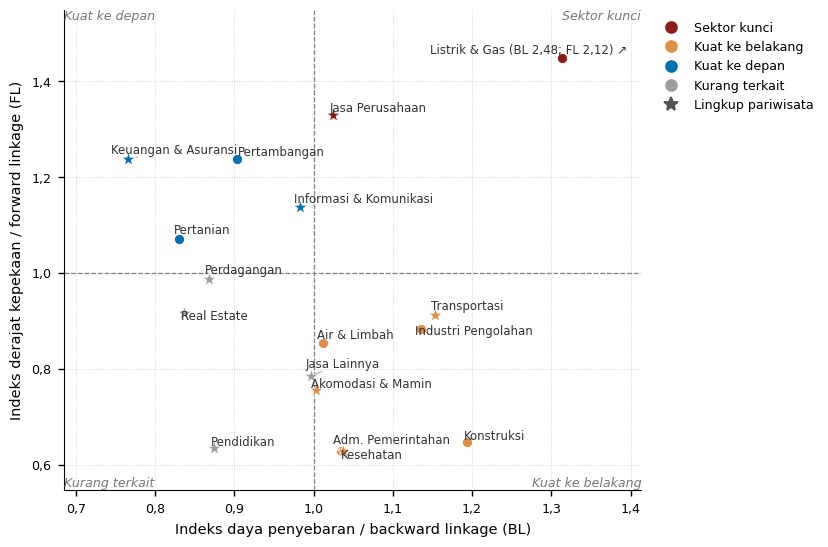

Gambar 1 tersimpan -> figur/4_4_01_klasifikasi_sektor_bali.png | .pdf


In [ ]:
WARNA_KL = {'Sektor kunci': C_BALI, 'Kuat ke belakang': C_INTRA,
            'Kuat ke depan': C_SPILL, 'Kurang terkait': '#9E9E9E'}

# Sektor dengan indeks > 2 digambar di tepi bidang agar sektor lain tidak berimpitan
d1 = df_link.copy()
biasa = (d1['BL_norm'] <= 2) & (d1['FL_norm'] <= 2)
BATAS_X = d1.loc[biasa, 'BL_norm'].max() + 0.12
BATAS_Y = d1.loc[biasa, 'FL_norm'].max() + 0.12
d1['px'] = d1['BL_norm'].clip(upper=BATAS_X)
d1['py'] = d1['FL_norm'].clip(upper=BATAS_Y)
d1['label'] = [s if b else f'{s} (BL {fmt(x, 2)}; FL {fmt(y, 2)}) \u2197'
               for s, b, x, y in zip(d1['Sektor_singkat'], biasa, d1['BL_norm'], d1['FL_norm'])]

fig, ax = plt.subplots(figsize=(LEBAR, 105 * MM), layout='constrained')
for _, r in d1.iterrows():
    ax.scatter(r['px'], r['py'], s=70 if r['Lingkup_Pariwisata'] else 32,
               marker='*' if r['Lingkup_Pariwisata'] else 'o',
               color=WARNA_KL[r['Klasifikasi']], edgecolor='white', lw=0.5, zorder=3)
teks = [ax.text(r['px'], r['py'], r['label'], fontsize=6.5, color=C_TEKS) for _, r in d1.iterrows()]
ax.axhline(1, ls='--', lw=0.7, color='#777777', zorder=1)
ax.axvline(1, ls='--', lw=0.7, color='#777777', zorder=1)

x0 = min(d1['px'].min(), 0.95) - 0.08; x1 = BATAS_X + 0.1
y0 = min(d1['py'].min(), 0.95) - 0.08; y1 = BATAS_Y + 0.1
ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
kw = dict(fontsize=7, color='#777777', fontstyle='italic')
ax.text(x1, y1, 'Sektor kunci', ha='right', va='top', **kw)
ax.text(x0, y1, 'Kuat ke depan', ha='left', va='top', **kw)
ax.text(x1, y0, 'Kuat ke belakang', ha='right', va='bottom', **kw)
ax.text(x0, y0, 'Kurang terkait', ha='left', va='bottom', **kw)
adjust_text(teks, ax=ax, arrowprops=dict(arrowstyle='-', lw=0.4, color='#888888'))

ax.set_xlabel('Indeks daya penyebaran / backward linkage (BL)')
ax.set_ylabel('Indeks derajat kepekaan / forward linkage (FL)')
ax.legend(handles=[Line2D([], [], marker='o', ls='', color=c, label=k) for k, c in WARNA_KL.items()] +
                  [Line2D([], [], marker='*', ls='', color='#555555', ms=8, label='Lingkup pariwisata')],
          loc='upper left', bbox_to_anchor=(1.01, 1), ncol=1)
ax.grid(ls=':', lw=0.5, alpha=0.6)

simpan(fig, '4_4_01_klasifikasi_sektor_bali',
       'Klasifikasi sektor Bali berdasarkan backward dan forward linkage',
       catatan='BL dari invers Leontief, FL dari invers Ghosh; keduanya dinormalisasi terhadap rata-rata '
               '578 sektor-wilayah.\nSektor bertanda \u2197 berada di luar bidang gambar dan diletakkan di tepi; '
               'nilai aslinya tertera pada label.')

### 2.4 Gambar multiplier output intra dan interregional

Panjang batang menunjukkan multiplier output tiap sektor Bali. Batang dipisah menjadi bagian yang tertahan di Bali dan bagian yang mengalir ke provinsi lain. Angka di ujung batang adalah porsi kebocoran.

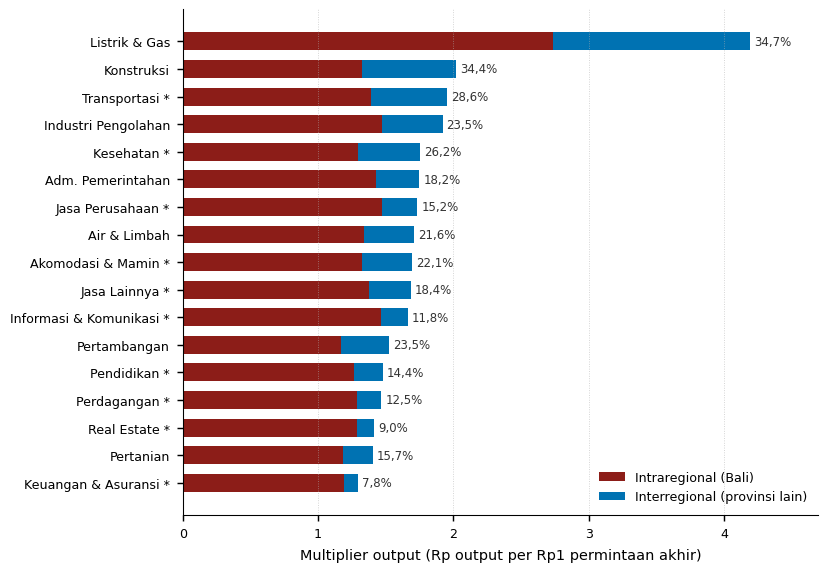

Gambar 2 tersimpan -> figur/4_4_02_multiplier_intra_inter.png | .pdf


In [ ]:
urut = df_link.sort_values('Multiplier_output')
fig, ax = plt.subplots(figsize=(LEBAR, 110 * MM), layout='constrained')
yy = np.arange(len(urut))
ax.barh(yy, urut['Multiplier_intra'], color=C_BALI, height=0.65, label='Intraregional (Bali)')
ax.barh(yy, urut['Multiplier_inter'], left=urut['Multiplier_intra'], color=C_SPILL, height=0.65,
        label='Interregional (provinsi lain)')
for y, (_, r) in zip(yy, urut.iterrows()):
    ax.text(r['Multiplier_output'] + 0.03, y, f'{fmt(r["Porsi_bocor_pct"], 1)}%',
            va='center', fontsize=6.5, color=C_TEKS)
ax.set_yticks(yy)
ax.set_yticklabels([f'{s}{" *" if p else ""}' for s, p in zip(urut['Sektor_singkat'], urut['Lingkup_Pariwisata'])])
ax.set_xlim(0, urut['Multiplier_output'].max() * 1.12)
ax.set_xlabel('Multiplier output (Rp output per Rp1 permintaan akhir)')
ax.legend(loc='lower right')
ax.grid(axis='x', ls=':', lw=0.5, alpha=0.6)

simpan(fig, '4_4_02_multiplier_intra_inter',
       'Multiplier output sektor Bali menurut wilayah penerima',
       catatan='Angka di ujung batang = porsi multiplier yang mengalir ke luar Bali. '
               'Tanda * = sektor lingkup pariwisata.')

---
## Bagian 3 — Vektor Shock

### 3.1 Memuat dan memeriksa $\Delta f$

Vektor $\Delta f$ (578 × 1) berasal dari Shock_Constructor_Bali, dengan

$$\Delta f_j = -\pi_j f_j$$

Proporsi shock $\pi$ disusun dari indikator remote sensing, big data, dan statistik resmi, sedangkan $f$ adalah permintaan akhir pada tabel IRIO 2025. Berkas rincian `06. delta_f_detail.csv` memuat $\pi$ per sektor, sehingga hubungan di atas dapat diperiksa ulang di sini.

Vektor hasilnya diperiksa dengan lima syarat:

1. Dimensinya 578.
2. Seluruh nilai nol atau negatif, karena skenarionya kontraksi.
3. Shock hanya berada di blok Bali.
4. Nilainya konsisten dengan $\pi$ dan $f$, serta sama dengan berkas rincian.
5. Uji kelayakan: besar shock tidak melebihi permintaan akhir sektornya ($|\Delta f_j| \le f_j$). Jika dilanggar, permintaan akhir setelah shock menjadi negatif dan tidak bermakna ekonomi.

In [ ]:
delta_f = np.load(F_DELTAF).astype(float).ravel()
detail  = pd.read_csv(F_DETAIL)

assert delta_f.shape == (N_TOTAL,), f'Dimensi delta_f {delta_f.shape}'
assert (delta_f <= 0).all(), 'Ada delta_f positif'
luar_blok = np.r_[delta_f[:BALI.start], delta_f[BALI.stop:]]
assert (luar_blok == 0).all(), 'Ada shock di luar blok Bali'
detail = detail.sort_values('Index_IRIO')
assert np.allclose(detail['DeltaFD_juta_Rp'].values, delta_f), 'delta_f tidak sama dengan berkas rincian'

df_b  = delta_f[BALI]
fd_b  = FD[BALI]
rasio = np.where(fd_b > 0, -df_b / fd_b, np.nan)

df_uji = pd.DataFrame({
    'Kode_S': KODE_S, 'KBLI': KBLI, 'Sektor_singkat': SEKTOR_SINGKAT,
    'FD_awal_triliun': (fd_b / 1e6).round(4),
    'Shock_triliun': (-df_b / 1e6).round(4),
    'FD_sesudah_triliun': ((fd_b + df_b) / 1e6).round(4),
    'Proporsi_shock_pct': (rasio * 100).round(2),
    'Layak': np.where(-df_b <= fd_b, 'ya', 'TIDAK'),
})
display(df_uji[df_uji['Shock_triliun'] > 0])

n_tidak = (df_uji['Layak'] == 'TIDAK').sum()
assert n_tidak == 0, f'{n_tidak} sektor menerima shock melebihi permintaan akhirnya'

total_shock = delta_f.sum()
print(f'Sektor yang menerima shock : {(df_b != 0).sum()} dari {N_SEK}')
print(f'Total shock (delta_f)      : Rp{fmt(total_shock / 1e6)} triliun')
print(f'Permintaan akhir Bali      : Rp{fmt(fd_b.sum() / 1e6)} -> Rp{fmt((fd_b + df_b).sum() / 1e6)} triliun '
      f'(turun {fmt(-total_shock / fd_b.sum() * 100, 1)}%)')

,Kode_S,KBLI,Sektor_singkat,FD_awal_triliun,Shock_triliun,FD_sesudah_triliun,Proporsi_shock_pct,Layak
6,S7,G,Perdagangan,21.0336,7.4028,13.6308,35.19,ya
7,S8,H,Transportasi,49.0841,20.2820,28.8021,41.32,ya
8,S9,I,Akomodasi & Mamin,99.4366,27.5751,71.8615,27.73,ya
9,S10,J,Informasi & Komunikasi,12.3279,4.9498,7.3781,40.15,ya
10,S11,K,Keuangan & Asuransi,7.9660,3.1984,4.7675,40.15,ya
11,S12,L,Real Estate,9.8465,2.5737,7.2728,26.14,ya
12,S13,"M,N",Jasa Perusahaan,1.3538,0.5436,0.8102,40.15,ya
14,S15,P,Pendidikan,19.5725,9.5295,10.0430,48.69,ya
15,S16,Q,Kesehatan,12.7529,5.7551,6.9978,45.13,ya
16,S17,"R,S,T,U",Jasa Lainnya,7.3923,2.5819,4.8103,34.93,ya


Sektor yang menerima shock : 10 dari 17
Total shock (delta_f)      : Rp-84,39 triliun
Permintaan akhir Bali      : Rp395,65 -> Rp311,26 triliun (turun 21,3%)


### 3.2 Gambar besaran shock

Batang abu-abu adalah permintaan akhir awal tiap sektor Bali. Bagian merah adalah shock yang diinjeksikan, dengan persentase penurunannya di ujung batang. Sektor tanpa shock tetap ditampilkan supaya proporsinya terlihat utuh.

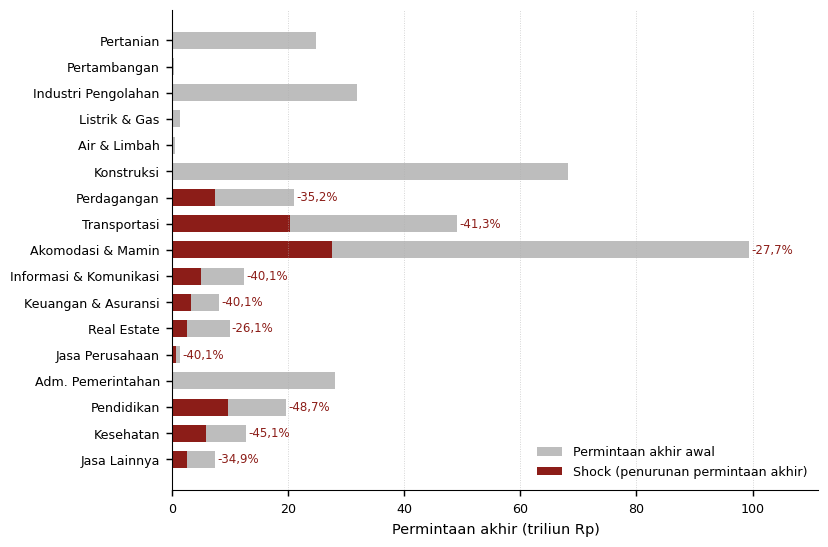

Gambar 3 tersimpan -> figur/4_4_03_shock_permintaan_akhir.png | .pdf


In [ ]:
u = df_uji.iloc[::-1]
fig, ax = plt.subplots(figsize=(LEBAR, 105 * MM), layout='constrained')
yy = np.arange(N_SEK)
ax.barh(yy, u['FD_awal_triliun'], color=C_ABU, height=0.65, label='Permintaan akhir awal')
ax.barh(yy, u['Shock_triliun'], color=C_BALI, height=0.65, label='Shock (penurunan permintaan akhir)')
for y, (_, r) in zip(yy, u.iterrows()):
    if r['Shock_triliun'] > 0:
        ax.text(r['FD_awal_triliun'] + 0.4, y, f'-{fmt(r["Proporsi_shock_pct"], 1)}%',
                va='center', fontsize=6.5, color=C_BALI)
ax.set_yticks(yy); ax.set_yticklabels(u['Sektor_singkat'])
ax.set_xlabel('Permintaan akhir (triliun Rp)')
ax.set_xlim(0, u['FD_awal_triliun'].max() * 1.12)
ax.legend(loc='lower right')
ax.grid(axis='x', ls=':', lw=0.5, alpha=0.6)

simpan(fig, '4_4_03_shock_permintaan_akhir',
       'Shock permintaan akhir per sektor di Provinsi Bali',
       catatan='Persentase = proporsi shock terhadap permintaan akhir sektor (hasil Shock_Constructor).')

---
## Bagian 4 — Simulasi Leontief

Perubahan output di seluruh 578 sektor-wilayah dihitung sekaligus:

$$\Delta x = L\,\Delta f$$

Persamaan ini menangkap rambatan langsung maupun tidak langsung, termasuk ke sektor dan provinsi yang tidak menerima shock. **Multiplier efektif** adalah rasio total perubahan output terhadap total shock:

$$m^{ef} = \frac{\mathbf{1}^\top \Delta x}{\mathbf{1}^\top \Delta f}$$

Nilai ini adalah rata-rata multiplier sektor Bali yang dibobot dengan komposisi shock.

In [ ]:
delta_x     = L @ delta_f
DX          = delta_x.reshape(N_PROV, N_SEK)       # [provinsi, sektor]
dampak_prov = DX.sum(axis=1)
dampak_sek  = DX.sum(axis=0)

dx_nasional  = delta_x.sum()
dx_bali      = dampak_prov[IDX_BALI]
dx_spillover = dx_nasional - dx_bali
mult_ef      = dx_nasional / total_shock

ringkasan_sim = pd.DataFrame({
    'Besaran': ['Shock permintaan akhir', 'Dampak output nasional', 'Dampak output di Bali',
                'Spillover ke luar Bali', 'Multiplier efektif'],
    'Nilai': [f'Rp{fmt(total_shock / 1e6)} T', f'Rp{fmt(dx_nasional / 1e6)} T',
              f'Rp{fmt(dx_bali / 1e6)} T ({fmt(dx_bali / dx_nasional * 100, 1)}%)',
              f'Rp{fmt(dx_spillover / 1e6)} T ({fmt(dx_spillover / dx_nasional * 100, 1)}%)',
              fmt(mult_ef, 4)],
}).set_index('Besaran')
display(ringkasan_sim)
print(f'Setiap Rp1 penurunan permintaan akhir pariwisata Bali menurunkan output nasional Rp{fmt(mult_ef)}.')

,Nilai
Besaran,
Shock permintaan akhir,"Rp-84,39 T"
Dampak output nasional,"Rp-142,65 T"
Dampak output di Bali,"Rp-112,43 T (78,8%)"
Spillover ke luar Bali,"Rp-30,22 T (21,2%)"
Multiplier efektif,"1,6903"


Setiap Rp1 penurunan permintaan akhir pariwisata Bali menurunkan output nasional Rp1,69.


---
## Bagian 5 — Dekomposisi Dampak

Total dampak dipecah menjadi empat komponen, mengikuti logika dekomposisi multiplier regional Miyazawa (1966) dan Round (1985). Misalkan $A_{BB}$ adalah blok koefisien Bali–Bali dan $L_{BB} = (I - A_{BB})^{-1}$ invers Leontief Bali yang diperlakukan tertutup.

| Komponen | Rumus | Makna |
|---|---|---|
| Efek langsung | $\Delta f_B$ | Penurunan permintaan akhir itu sendiri |
| Efek tidak langsung intraregional | $L_{BB}\Delta f_B - \Delta f_B$ | Rambatan antarsektor di dalam Bali |
| Efek umpan balik (*feedback*) | $\Delta x_B - L_{BB}\Delta f_B$ | Dampak yang keluar dari Bali lalu kembali ke Bali melalui pembelian input provinsi lain |
| Spillover interregional | $\sum_{r \ne B} \Delta x_r$ | Dampak di 33 provinsi lain |

Keempat komponen berjumlah persis sama dengan $\mathbf{1}^\top \Delta x$. Hal ini diuji dengan `assert`.

In [ ]:
A_BB = A[BALI, BALI]
L_BB = np.linalg.inv(np.eye(N_SEK) - A_BB)

dx_intra_vec  = L_BB @ df_b                 # dampak Bali bila Bali tertutup
langsung_vec  = df_b
tl_intra_vec  = dx_intra_vec - df_b
feedback_vec  = DX[IDX_BALI] - dx_intra_vec

komponen = {
    'Efek langsung'                     : langsung_vec.sum(),
    'Efek tidak langsung intraregional' : tl_intra_vec.sum(),
    'Efek umpan balik (feedback)'       : feedback_vec.sum(),
    'Spillover interregional'           : dx_spillover,
}
assert abs(sum(komponen.values()) - dx_nasional) < 1e-4, 'Dekomposisi tidak menjumlah ke total'
assert abs(sum(list(komponen.values())[:3]) - dx_bali) < 1e-4

df_dekom = pd.DataFrame({
    'Komponen': list(komponen) + ['Total dampak'],
    'Dampak_juta': list(komponen.values()) + [dx_nasional],
})
df_dekom['Dampak_triliun'] = (df_dekom['Dampak_juta'] / 1e6).round(4)
df_dekom['Porsi_pct']      = (df_dekom['Dampak_juta'] / dx_nasional * 100).round(3)
df_dekom['Multiplier_komponen'] = (df_dekom['Dampak_juta'] / total_shock).round(4)
display(df_dekom.set_index('Komponen'))

df_dekom_sek = pd.DataFrame({
    'Kode_S': KODE_S, 'Sektor_singkat': SEKTOR_SINGKAT,
    'Langsung_T': (langsung_vec / 1e6).round(4), 'TL_intra_T': (tl_intra_vec / 1e6).round(4),
    'Feedback_T': (feedback_vec / 1e6).round(5), 'Total_Bali_T': (DX[IDX_BALI] / 1e6).round(4),
})
print(f'\nFeedback hanya {fmt(abs(komponen["Efek umpan balik (feedback)"]) / abs(dx_bali) * 100, 3)}% '
      'dari dampak Bali: dampak yang keluar dari Bali hampir tidak kembali.')

,Dampak_juta,Dampak_triliun,Porsi_pct,Multiplier_komponen
Komponen,,,,
Efek langsung,-8.439190e+07,-84.3919,59.160,1.0000
Efek tidak langsung intraregional,-2.801028e+07,-28.0103,19.636,0.3319
Efek umpan balik (feedback),-2.341507e+04,-0.0234,0.016,0.0003
Spillover interregional,-3.022370e+07,-30.2237,21.187,0.3581
Total dampak,-1.426493e+08,-142.6493,100.000,1.6903



Feedback hanya 0,021% dari dampak Bali: dampak yang keluar dari Bali hampir tidak kembali.


### 5.1 Gambar dekomposisi (grafik air terjun)

Batang mengambang menunjukkan tambahan tiap komponen. Batang penuh menunjukkan subtotal dampak di Bali dan total dampak nasional. Seluruh nilai ditampilkan sebagai besaran penurunan output.

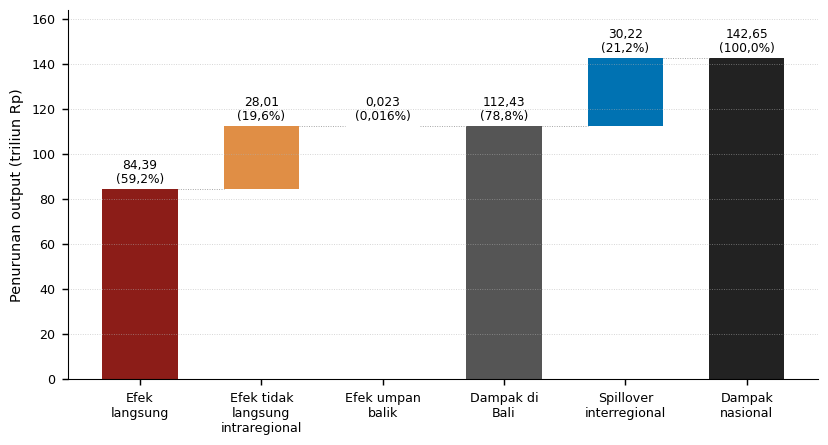

Gambar 4 tersimpan -> figur/4_4_04_dekomposisi_dampak.png | .pdf


In [ ]:
v = {k: abs(val) / 1e6 for k, val in komponen.items()}
langkah = [
    ('Efek\nlangsung',                 v['Efek langsung'],                     'naik', C_BALI),
    ('Efek tidak\nlangsung\nintraregional', v['Efek tidak langsung intraregional'], 'naik', C_INTRA),
    ('Efek umpan\nbalik',              v['Efek umpan balik (feedback)'],       'naik', C_FEEDBACK),
    ('Dampak di\nBali',                abs(dx_bali) / 1e6,                     'total', '#555555'),
    ('Spillover\ninterregional',       v['Spillover interregional'],           'naik', C_SPILL),
    ('Dampak\nnasional',               abs(dx_nasional) / 1e6,                 'total', '#222222'),
]
fig, ax = plt.subplots(figsize=(LEBAR, 85 * MM), layout='constrained')
dasar = 0
for i, (lab, val, jenis, c) in enumerate(langkah):
    bawah = 0 if jenis == 'total' else dasar
    ax.bar(i, val, bottom=bawah, color=c, width=0.62)
    d = 3 if val < 0.1 else 2
    ax.text(i, bawah + val + abs(dx_nasional) / 1e6 * 0.012,
            f'{fmt(val, d)}\n({fmt(val / (abs(dx_nasional) / 1e6) * 100, 1 if val >= 0.1 else 3)}%)',
            ha='center', va='bottom', fontsize=6.8, linespacing=1.1)
    if jenis == 'naik':
        dasar += val
    if i < len(langkah) - 1:
        ax.plot([i + 0.31, i + 0.69], [dasar, dasar], color='#999999', lw=0.5, ls=':')
ax.set_xticks(range(len(langkah))); ax.set_xticklabels([l[0] for l in langkah], fontsize=7)
ax.set_ylabel('Penurunan output (triliun Rp)')
ax.set_ylim(0, abs(dx_nasional) / 1e6 * 1.15)
ax.grid(axis='y', ls=':', lw=0.5, alpha=0.6)

simpan(fig, '4_4_04_dekomposisi_dampak',
       'Dekomposisi dampak shock pariwisata Bali terhadap output',
       catatan='Angka dalam kurung = porsi terhadap dampak nasional. '
               'Dekomposisi mengikuti Miyazawa (1966) dan Round (1985).')

### 5.2 Dampak terhadap nilai tambah (PDRB)

Penurunan output belum sama dengan kehilangan PDRB, karena sebagian output merupakan input antara yang nilainya sudah terhitung di sektor lain. Untuk menghindari penghitungan ganda, perubahan output dikalikan dengan koefisien nilai tambah tiap sektor-wilayah:

$$v_j = \frac{NTB_j}{x_j}, \qquad \Delta PDRB = \hat{v}\,\Delta x$$

Rasio $\Delta PDRB / \Delta f$ disebut multiplier nilai tambah. Nilainya lebih kecil daripada multiplier output karena hanya menghitung nilai tambah yang benar-benar tercipta.

In [ ]:
v = NTB / x
assert ((v >= 0) & (v <= 1)).all(), 'Ada koefisien nilai tambah di luar [0, 1]'

delta_v     = v * delta_x
DV          = delta_v.reshape(N_PROV, N_SEK)
dv_nasional = delta_v.sum()
dv_bali     = DV[IDX_BALI].sum()

df_pdrb = pd.DataFrame({
    'Besaran': ['Dampak PDRB nasional', 'Dampak PDRB Bali', 'Dampak PDRB provinsi lain',
                'Multiplier nilai tambah', 'Dampak relatif terhadap PDRB Bali'],
    'Nilai': [f'Rp{fmt(dv_nasional / 1e6)} T', f'Rp{fmt(dv_bali / 1e6)} T',
              f'Rp{fmt((dv_nasional - dv_bali) / 1e6)} T',
              fmt(dv_nasional / delta_f.sum(), 4),
              f'{fmt(abs(dv_bali) / NTB[BALI].sum() * 100, 2)}% dari PDRB Bali'],
}).set_index('Besaran')
display(df_pdrb)
print(f'Nilai tambah rata-rata {fmt(v.mean() * 100, 1)}% dari output, '
      'sehingga dampak PDRB lebih kecil daripada dampak output.')

,Nilai
Besaran,
Dampak PDRB nasional,"Rp-81,10 T"
Dampak PDRB Bali,"Rp-65,27 T"
Dampak PDRB provinsi lain,"Rp-15,83 T"
Multiplier nilai tambah,"0,9610"
Dampak relatif terhadap PDRB Bali,"20,54% dari PDRB Bali"


Nilai tambah rata-rata 57,7% dari output, sehingga dampak PDRB lebih kecil daripada dampak output.


---
## Bagian 6 — Sebaran Dampak

### 6.1 Dampak per provinsi

Dampak tiap provinsi dilaporkan dalam dua ukuran:

- **Nominal**: $\Delta x_r$ dalam rupiah. Ukuran ini menunjukkan provinsi yang menanggung kerugian terbesar.
- **Intensitas**: $|\Delta x_r| / x_r \times 100$. Ukuran ini menunjukkan seberapa besar dampak tersebut terhadap perekonomian provinsi itu sendiri.

Kedua ukuran bisa memberi peringkat berbeda. Provinsi besar seperti Jawa Timur mungkin menerima nominal terbesar dengan intensitas kecil, sementara provinsi tetangga yang kecil bisa sebaliknya.

**Koefisien struktural** $\sum_{i \in r}\sum_{j \in B} l_{ij}$ menyatakan intensitas keterkaitan blok Bali dengan provinsi $r$ tanpa bobot shock. Koefisien ini diekspor untuk Tujuan 3.

In [ ]:
intensitas = np.abs(dampak_prov) / X_PROV * 100
koef_struktural = np.array([L[p * N_SEK:(p + 1) * N_SEK, BALI].sum() if p != IDX_BALI else 0.0
                            for p in range(N_PROV)])

df_prov = pd.DataFrame({
    'IDX': range(N_PROV), 'Provinsi': PROV_NAMES,
    'Dx_juta': dampak_prov.round(2), 'Dx_triliun': (dampak_prov / 1e6).round(4),
    'Pct_nasional': (dampak_prov / dx_nasional * 100).round(3),
    'Output_triliun': (X_PROV / 1e6).round(2),
    'Intensitas_pct': intensitas.round(5),
    'Koef_Struktural_L': koef_struktural.round(6),
    'dPDRB_triliun': (DV.sum(axis=1) / 1e6).round(4),
    'Tipe': np.where(LUAR, 'Spillover', 'Wilayah terdampak langsung'),
    'Lat': [KOORD[p][0] for p in PROV_NAMES], 'Lon': [KOORD[p][1] for p in PROV_NAMES],
})
luar = df_prov[LUAR]
print('Sepuluh provinsi penerima spillover terbesar (nominal):')
display(luar.sort_values('Dx_juta')[['Provinsi', 'Dx_triliun', 'Pct_nasional', 'Intensitas_pct']].head(10)
        .reset_index(drop=True))
print('Sepuluh provinsi dengan intensitas dampak tertinggi:')
display(luar.sort_values('Intensitas_pct', ascending=False)[['Provinsi', 'Dx_triliun', 'Intensitas_pct']]
        .head(10).reset_index(drop=True))

sp = np.abs(luar['Dx_juta'].values)
print(f'Intensitas dampak di Bali              : {fmt(intensitas[IDX_BALI], 3)}% dari output Bali')
print(f'Lima provinsi teratas menyerap         : {fmt(np.sort(sp)[::-1][:5].sum() / sp.sum() * 100, 1)}% spillover')
rho_ni, p_ni = stats.spearmanr(np.abs(luar['Dx_juta']), luar['Intensitas_pct'])
print(f'Spearman nominal vs intensitas (N=33)  : rho = {rho_ni:.3f}, p = {p_ni:.3g}')

Sepuluh provinsi penerima spillover terbesar (nominal):


,Provinsi,Dx_triliun,Pct_nasional,Intensitas_pct
0,Jawa Timur,-6.8259,4.785,0.11295
1,DKI Jakarta,-4.5349,3.179,0.06230
2,Sumatera Selatan,-3.7477,2.627,0.27814
3,Jawa Tengah,-3.7244,2.611,0.09574
4,Banten,-1.6524,1.158,0.09374
5,Sulawesi Selatan,-1.5436,1.082,0.12375
6,Jawa Barat,-1.5150,1.062,0.02678
7,Kalimantan Timur,-1.3754,0.964,0.08013
8,Riau,-1.0827,0.759,0.05545
9,Nusa Tenggara Barat,-0.7711,0.541,0.24018


Sepuluh provinsi dengan intensitas dampak tertinggi:


,Provinsi,Dx_triliun,Intensitas_pct
0,Sumatera Selatan,-3.7477,0.27814
1,Nusa Tenggara Barat,-0.7711,0.24018
2,Nusa Tenggara Timur,-0.4414,0.18952
3,Sulawesi Selatan,-1.5436,0.12375
4,Jawa Timur,-6.8259,0.11295
5,Jawa Tengah,-3.7244,0.09574
6,Banten,-1.6524,0.09374
7,Kalimantan Timur,-1.3754,0.08013
8,DKI Jakarta,-4.5349,0.06230
9,Riau,-1.0827,0.05545


Intensitas dampak di Bali              : 19,480% dari output Bali
Lima provinsi teratas menyerap         : 67,8% spillover
Spearman nominal vs intensitas (N=33)  : rho = 0.821, p = 4.78e-09


### 6.2 Gambar peringkat provinsi

Panel (a) mengurutkan 15 provinsi menurut besaran spillover nominal. Panel (b) mengurutkan 15 provinsi menurut intensitasnya. Warna batang yang sama menandai provinsi yang muncul di kedua panel.

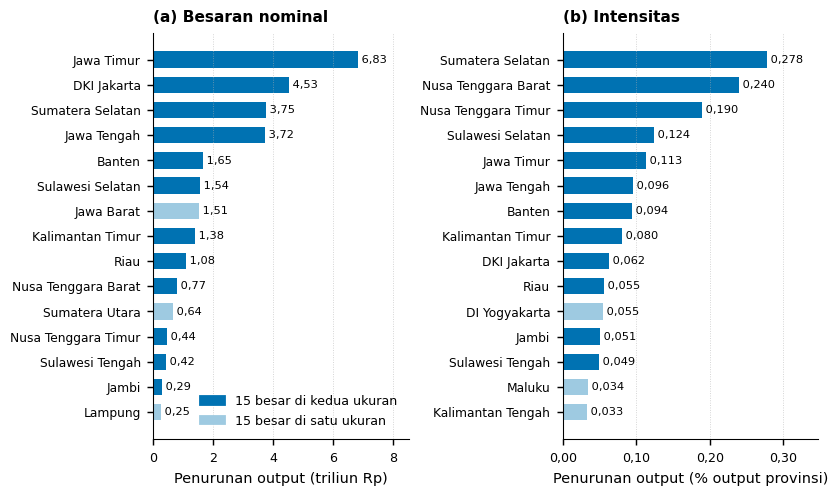

Gambar 5 tersimpan -> figur/4_4_05_peringkat_provinsi.png | .pdf


In [ ]:
top_n = luar.assign(abs_T=np.abs(luar['Dx_triliun'])).sort_values('abs_T', ascending=False).head(15)
top_i = luar.sort_values('Intensitas_pct', ascending=False).head(15)
irisan = set(top_n['Provinsi']) & set(top_i['Provinsi'])

fig, axs = plt.subplots(1, 2, figsize=(LEBAR, 95 * MM), layout='constrained')
for ax, d, kol, xl, dec, judul in [
        (axs[0], top_n, 'abs_T', 'Penurunan output (triliun Rp)', 2, '(a) Besaran nominal'),
        (axs[1], top_i, 'Intensitas_pct', 'Penurunan output (% output provinsi)', 3, '(b) Intensitas')]:
    d = d.iloc[::-1]
    c = [C_SPILL if p in irisan else '#9ECAE1' for p in d['Provinsi']]
    ax.barh(range(len(d)), d[kol], color=c, height=0.65)
    for y, val in enumerate(d[kol]):
        ax.text(val, y, ' ' + fmt(val, dec), va='center', fontsize=6.3)
    ax.set_yticks(range(len(d))); ax.set_yticklabels(d['Provinsi'], fontsize=6.8)
    ax.set_xlabel(xl); ax.set_title(judul)
    ax.set_xlim(0, d[kol].max() * 1.25)
    ax.grid(axis='x', ls=':', lw=0.5, alpha=0.6)
axs[0].legend(handles=[Patch(color=C_SPILL, label='15 besar di kedua ukuran'),
                       Patch(color='#9ECAE1', label='15 besar di satu ukuran')],
              loc='lower right')

simpan(fig, '4_4_05_peringkat_provinsi',
       'Lima belas provinsi penerima spillover terbesar menurut nominal dan intensitas',
       catatan='Bali tidak ditampilkan. Intensitas = |Δx| terhadap output provinsi.')

### 6.3 Peta intensitas dampak

Batas provinsi diambil dari GeoJSON 34 provinsi (BAKOSURTANAL 1:250.000). Warna memakai skala logaritmik karena intensitas antarprovinsi berbeda beberapa orde besaran. Bali diarsir terpisah karena merupakan wilayah asal shock.

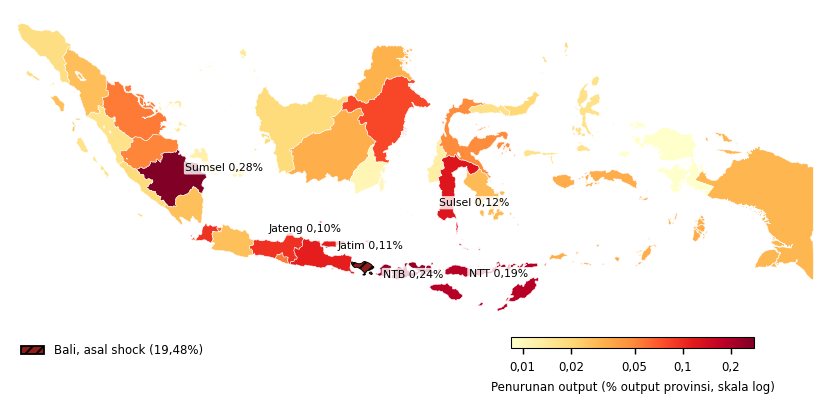

Gambar 6 tersimpan -> figur/4_4_06_peta_intensitas.png | .pdf


In [ ]:
F_GEO = IN_DIR + 'indonesia_prov.geojson'
if not os.path.exists(F_GEO):
    r = requests.get('https://raw.githubusercontent.com/ans-4175/peta-indonesia-geojson/'
                     'master/indonesia-prov.geojson', timeout=120)
    r.raise_for_status(); open(F_GEO, 'wb').write(r.content)

NAMA_GEOJSON = {'Aceh': 'DI. ACEH', 'Kep. Bangka Belitung': 'BANGKA BELITUNG',
                'Kep. Riau': 'KEPULAUAN RIAU', 'DI Yogyakarta': 'DAERAH ISTIMEWA YOGYAKARTA',
                'Nusa Tenggara Barat': 'NUSATENGGARA BARAT'}
gdf = gpd.read_file(F_GEO)
gdf['geometry'] = gdf.geometry.buffer(0)
kunci = {NAMA_GEOJSON.get(p, p.upper()): i for i, p in enumerate(PROV_NAMES)}
gdf['IDX'] = gdf['Propinsi'].str.upper().str.strip().map(kunci)
assert gdf['IDX'].notna().sum() == N_PROV, 'Ada provinsi yang belum cocok dengan GeoJSON'
gdf = gdf.dropna(subset=['IDX']).astype({'IDX': int})
gdf['Intensitas'] = intensitas[gdf['IDX']]
XLIM, YLIM = (94.8, 141.3), (-14.6, 6.4)   # ruang laut di selatan untuk legenda dan skala warna

def peta_dasar(ax, warna='#EFEFEF'):
    gdf.plot(ax=ax, color=warna, edgecolor='white', linewidth=0.3)
    ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect('equal'); ax.set_axis_off()

luar_g = gdf['IDX'] != IDX_BALI
vmin, vmax = gdf.loc[luar_g, 'Intensitas'].min(), gdf.loc[luar_g, 'Intensitas'].max()
norm_i = mcolors.LogNorm(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(LEBAR, 80 * MM), layout='constrained')
gdf[luar_g].plot(column='Intensitas', ax=ax, cmap='YlOrRd', norm=norm_i, edgecolor='white', lw=0.3)
gdf[~luar_g].plot(ax=ax, color=C_BALI, edgecolor='black', lw=0.5, hatch='////')
ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect('equal'); ax.set_axis_off()

label = luar.sort_values('Intensitas_pct', ascending=False).head(6)
teks = [ax.text(r['Lon'], r['Lat'], f'{singkat(r["Provinsi"])} {fmt(r["Intensitas_pct"], 2)}%',
                fontsize=6, zorder=6, bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))
        for _, r in label.iterrows()]
adjust_text(teks, ax=ax, arrowprops=dict(arrowstyle='-', lw=0.4, color='#444444'))

cax = ax.inset_axes([0.62, 0.075, 0.30, 0.03])
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm_i, cmap='YlOrRd'), cax=cax, orientation='horizontal')
cb.set_label('Penurunan output (% output provinsi, skala log)', fontsize=6.5)
atur_cbar_log(cb, vmin, vmax)
ax.legend(handles=[Patch(facecolor=C_BALI, edgecolor='black', hatch='////',
                         label=f'Bali, asal shock ({fmt(intensitas[IDX_BALI], 2)}%)')],
          loc='lower left', bbox_to_anchor=(0.0, 0.02), fontsize=6.5)

simpan(fig, '4_4_06_peta_intensitas',
       'Intensitas dampak shock pariwisata Bali terhadap output provinsi',
       sumber=SUMBER_IRIO + ' Batas wilayah: BAKOSURTANAL 1:250.000.',
       catatan='Label menunjukkan enam provinsi dengan intensitas tertinggi.')

### 6.4 Dampak per sektor di Bali

Dampak tiap sektor Bali dipecah menjadi efek langsung, efek tidak langsung intraregional, dan efek umpan balik, mengikuti Bagian 5. Sektor di luar lingkup pariwisata hanya menerima dampak tidak langsung. Dampak pada sektor-sektor ini murni hasil keterkaitan input–output.

,Kode_S,Sektor_singkat,Langsung_T,TL_intra_T,Feedback_T,Total_Bali_T
0,S9,Akomodasi & Mamin,-27.5751,-3.0041,-0.00348,-30.5827
1,S8,Transportasi,-20.2820,-3.1425,-0.00538,-23.4298
2,S15,Pendidikan,-9.5295,-0.3037,-0.00003,-9.8332
3,S7,Perdagangan,-7.4028,-2.3930,-0.00325,-9.7990
4,S10,Informasi & Komunikasi,-4.9498,-4.0174,-0.00076,-8.9680
5,S11,Keuangan & Asuransi,-3.1984,-3.2275,-0.00164,-6.4276
6,S16,Kesehatan,-5.7551,-0.1171,-0.00032,-5.8725
7,S1,Pertanian,0.0000,-3.7649,-0.00471,-3.7696
8,S12,Real Estate,-2.5737,-1.1922,-0.00045,-3.7664
9,S17,Jasa Lainnya,-2.5819,-0.4426,-0.00023,-3.0248


Dampak pada sektor Bali tanpa shock langsung: Rp-9,0620 T (8,1% dampak Bali)


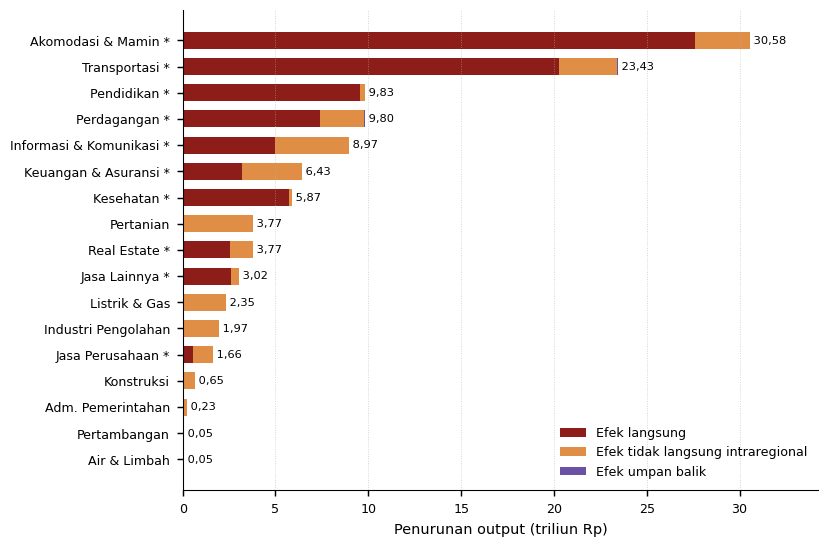

Gambar 7 tersimpan -> figur/4_4_07_dampak_sektor_bali.png | .pdf


In [ ]:
display(df_dekom_sek.sort_values('Total_Bali_T').reset_index(drop=True))
tanpa = [i for i in range(N_SEK) if df_b[i] == 0]
print(f'Dampak pada sektor Bali tanpa shock langsung: Rp{fmt(DX[IDX_BALI, tanpa].sum() / 1e6, 4)} T '
      f'({fmt(DX[IDX_BALI, tanpa].sum() / dx_bali * 100, 1)}% dampak Bali)')

d = df_dekom_sek.assign(tot=np.abs(df_dekom_sek['Total_Bali_T'])).sort_values('tot')
fig, ax = plt.subplots(figsize=(LEBAR, 105 * MM), layout='constrained')
yy = np.arange(N_SEK); kiri = np.zeros(N_SEK)
for kol, c, lab in [('Langsung_T', C_BALI, 'Efek langsung'),
                    ('TL_intra_T', C_INTRA, 'Efek tidak langsung intraregional'),
                    ('Feedback_T', C_FEEDBACK, 'Efek umpan balik')]:
    val = np.abs(d[kol].values)
    ax.barh(yy, val, left=kiri, color=c, height=0.65, label=lab); kiri += val
for y, t in zip(yy, kiri):
    ax.text(t, y, ' ' + fmt(t, 2), va='center', fontsize=6.3)
ax.set_yticks(yy)
ax.set_yticklabels([f'{s}{" *" if i in LINGKUP_PARIWISATA else ""}'
                    for s, i in zip(d['Sektor_singkat'], d.index)])
ax.set_xlabel('Penurunan output (triliun Rp)')
ax.set_xlim(0, kiri.max() * 1.12)
ax.legend(loc='lower right')
ax.grid(axis='x', ls=':', lw=0.5, alpha=0.6)

simpan(fig, '4_4_07_dampak_sektor_bali',
       'Dampak shock terhadap output sektor di Provinsi Bali menurut komponen',
       catatan='Tanda * = sektor lingkup pariwisata (menerima shock langsung). '
               'Efek umpan balik sangat kecil sehingga hampir tidak tampak.')

### 6.5 Spillover per sektor di luar Bali

Bagian ini menjawab sektor apa yang menjadi saluran spillover, yaitu sektor mana di 33 provinsi lain yang menanggung dampak. Nilainya adalah jumlah $\Delta x$ sektor tersebut di seluruh provinsi selain Bali.

,Kode_S,KBLI,Sektor_singkat,Spillover_triliun,Porsi_spillover_pct
0,S3,C,Industri Pengolahan,-14.7587,48.83
1,S7,G,Perdagangan,-3.7225,12.32
2,S1,A,Pertanian,-3.0891,10.22
3,S2,B,Pertambangan,-1.8043,5.97
4,S8,H,Transportasi,-1.6121,5.33
5,S4,D,Listrik & Gas,-1.2571,4.16
6,S10,J,Informasi & Komunikasi,-1.1671,3.86
7,S11,K,Keuangan & Asuransi,-0.9907,3.28
8,S9,I,Akomodasi & Mamin,-0.5828,1.93
9,S13,"M,N",Jasa Perusahaan,-0.5282,1.75


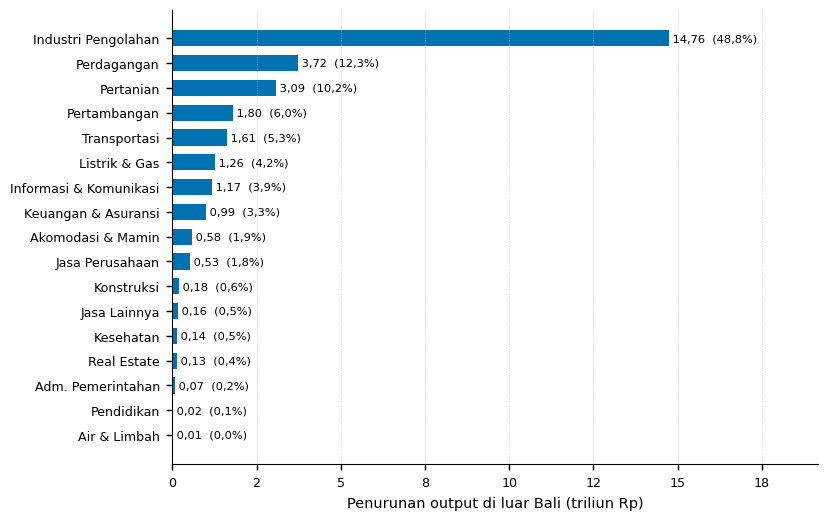

Gambar 8 tersimpan -> figur/4_4_08_spillover_sektor.png | .pdf


In [ ]:
spill_sek = DX[LUAR].sum(axis=0)
df_spill_sek = pd.DataFrame({
    'Kode_S': KODE_S, 'KBLI': KBLI, 'Sektor_singkat': SEKTOR_SINGKAT,
    'Spillover_triliun': (spill_sek / 1e6).round(4),
    'Porsi_spillover_pct': (spill_sek / dx_spillover * 100).round(2),
}).sort_values('Spillover_triliun').reset_index(drop=True)
display(df_spill_sek)

d = df_spill_sek.iloc[::-1]
fig, ax = plt.subplots(figsize=(LEBAR, 100 * MM), layout='constrained')
yy = np.arange(N_SEK)
ax.barh(yy, np.abs(d['Spillover_triliun']), color=C_SPILL, height=0.65)
for y, (_, r) in zip(yy, d.iterrows()):
    ax.text(abs(r['Spillover_triliun']), y,
            f' {fmt(abs(r["Spillover_triliun"]), 2)}  ({fmt(r["Porsi_spillover_pct"], 1)}%)',
            va='center', fontsize=6.3)
ax.set_yticks(yy); ax.set_yticklabels(d['Sektor_singkat'])
ax.set_xlabel('Penurunan output di luar Bali (triliun Rp)')
ax.set_xlim(0, np.abs(d['Spillover_triliun']).max() * 1.3)
ax.grid(axis='x', ls=':', lw=0.5, alpha=0.6)

simpan(fig, '4_4_08_spillover_sektor',
       'Spillover dampak ke luar Bali menurut sektor',
       catatan='Angka dalam kurung = porsi terhadap total spillover interregional.')

### 6.6 Matriks provinsi × sektor

Peta panas ini menggabungkan kedua dimensi untuk sepuluh provinsi penerima spillover terbesar. Setiap sel menunjukkan penurunan output sektor tertentu di provinsi tertentu dalam miliar rupiah. Warna memakai skala logaritmik.

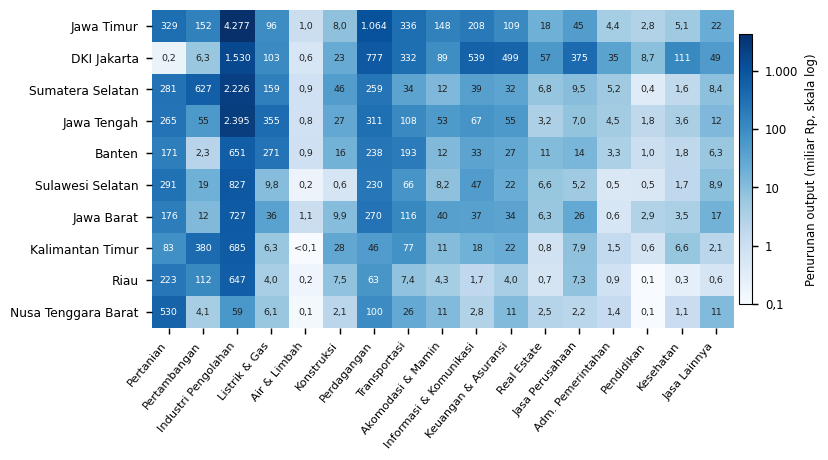

Gambar 9 tersimpan -> figur/4_4_09_matriks_provinsi_sektor.png | .pdf


In [ ]:
urut_p = np.argsort(np.abs(dampak_prov) * LUAR)[::-1][:10]
M = np.abs(DX[urut_p]) / 1e3                       # miliar Rp
df_matriks = pd.DataFrame(DX[LUAR] / 1e3, index=np.array(PROV_NAMES)[LUAR], columns=SEKTOR_SINGKAT)

pos_min = M[M > 0].min()
norm_h = mcolors.LogNorm(vmin=0.1, vmax=M.max())
fig, ax = plt.subplots(figsize=(LEBAR, 88 * MM), layout='constrained')
im = ax.imshow(np.clip(M, norm_h.vmin, None), cmap='Blues', norm=norm_h, aspect='auto')
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        val = M[i, j]
        warna_t = 'white' if norm_h(max(val, norm_h.vmin)) > 0.6 else '#222222'
        label = '<0,1' if val < 0.05 else fmt(val, 0 if val >= 10 else 1)
        ax.text(j, i, label, ha='center', va='center', fontsize=5.2, color=warna_t)
ax.set_xticks(range(N_SEK)); ax.set_xticklabels(SEKTOR_SINGKAT, rotation=50, ha='right', fontsize=6.3)
ax.set_yticks(range(len(urut_p))); ax.set_yticklabels([PROV_NAMES[p] for p in urut_p], fontsize=6.8)
ax.spines[:].set_visible(False)
cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.01)
cb.set_label('Penurunan output (miliar Rp, skala log)', fontsize=6.5)
atur_cbar_log(cb, norm_h.vmin, norm_h.vmax, pengali=(1,))

simpan(fig, '4_4_09_matriks_provinsi_sektor',
       'Sebaran spillover menurut provinsi dan sektor',
       catatan='Sepuluh provinsi penerima spillover terbesar, diurutkan dari atas. Nilai dalam miliar rupiah.')

---
## Bagian 7 — Jaringan Spillover

Bagian ini membaca hasil simulasi sebagai jaringan. Simpul adalah provinsi, dan sisi adalah aliran dampak atau aliran perdagangan input. Ada dua jaringan yang dianalisis:

1. **Jaringan aliran spillover.** Jaringan berbentuk bintang dari Bali ke tiap provinsi, dengan bobot sisi $|\Delta x_r|$. Jaringan ini menunjukkan ke mana dampak mengalir.
2. **Jaringan perdagangan input antarprovinsi.** Jaringan ini diagregasi dari $Z$ ke tingkat provinsi, $Z^{prov}_{rs} = \sum_{i\in r}\sum_{j\in s} z_{ij}$. Jaringan ini menunjukkan jalur yang memungkinkan dampak mengalir.

Perbandingan keduanya membedakan provinsi yang terdampak karena memasok Bali secara langsung dari provinsi yang terdampak lewat rantai tidak langsung.

### 7.1 Peta aliran spillover

Jumlah panah ditentukan dari data, bukan ambang arbitrer. Yang digambar adalah sejumlah minimum provinsi yang bersama-sama menutup 90% total spillover, dengan batas atas 15 provinsi. Seluruh 33 sisi tetap diekspor untuk Gephi.

11 provinsi teratas menutup 90,7% total spillover.


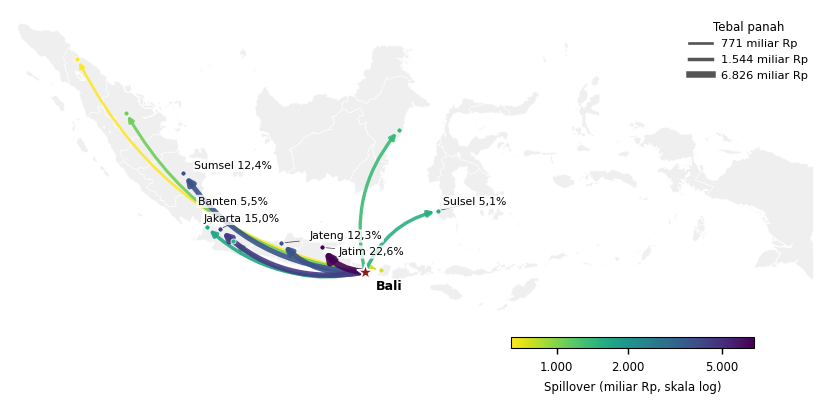

Gambar 10 tersimpan -> figur/4_4_10_peta_aliran_spillover.png | .pdf


In [ ]:
sp_abs = np.abs(dampak_prov) * LUAR
df_edges = pd.DataFrame([{
    'Source': IDX_BALI, 'Target': p, 'Type': 'Directed',
    'Source_Label': 'Bali', 'Target_Label': PROV_NAMES[p],
    'Weight': sp_abs[p], 'Spillover_triliun': round(dampak_prov[p] / 1e6, 5),
    'Share_pct': round(sp_abs[p] / sp_abs.sum() * 100, 3),
    'Koef_Struktural': round(koef_struktural[p], 6)} for p in np.where(LUAR)[0]])
df_edges = df_edges.sort_values('Weight', ascending=False).reset_index(drop=True)
df_edges['Share_kumulatif_pct'] = df_edges['Share_pct'].cumsum().round(3)

N_ARUS = min(int((df_edges['Share_kumulatif_pct'] < 90).sum() + 1), 15)
top = df_edges.head(N_ARUS)
print(f'{N_ARUS} provinsi teratas menutup {fmt(top["Share_pct"].sum(), 1)}% total spillover.')

fig, ax = plt.subplots(figsize=(LEBAR, 80 * MM), layout='constrained')
peta_dasar(ax)
vmin, vmax = top['Weight'].min() / 1e3, top['Weight'].max() / 1e3
norm = mcolors.LogNorm(vmin=vmin, vmax=vmax)
cmap = mpl.colormaps['viridis_r']
lebar = lambda w: 0.4 + 3.2 * np.sqrt(w / top['Weight'].max())
lat_a, lon_a = KOORD['Bali']
for _, r in top.sort_values('Weight').iterrows():
    lat_b, lon_b = KOORD[r['Target_Label']]
    c = cmap(norm(r['Weight'] / 1e3))
    rad = -0.25                                   # busur ke barat melengkung ke selatan (laut)
    ax.add_patch(FancyArrowPatch((lon_a, lat_a), (lon_b, lat_b), connectionstyle=f'arc3,rad={rad}',
                                 arrowstyle='-|>', mutation_scale=4 + 5 * np.sqrt(r['Weight'] / 1e3 / vmax),
                                 lw=lebar(r['Weight']), color=c, alpha=0.9, zorder=3))
    ax.scatter(lon_b, lat_b, s=8, color=c, edgecolor='white', lw=0.4, zorder=4)
teks = [ax.text(KOORD[r['Target_Label']][1], KOORD[r['Target_Label']][0],
                f'{singkat(r["Target_Label"])} {fmt(r["Share_pct"], 1)}%', fontsize=6, zorder=7,
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.8))
        for _, r in top.head(6).iterrows()]
adjust_text(teks, ax=ax, expand=(1.3, 1.6), arrowprops=dict(arrowstyle='-', lw=0.4, color='#444444'))
ax.scatter(lon_a, lat_a, s=90, marker='*', color=C_BALI, edgecolor='white', zorder=6)
ax.annotate('Bali', (lon_a, lat_a), xytext=(6, -10), textcoords='offset points',
            fontsize=7, fontweight='bold', ha='left')

cax = ax.inset_axes([0.62, 0.075, 0.30, 0.03])
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation='horizontal')
cb.set_label('Spillover (miliar Rp, skala log)', fontsize=6.5); atur_cbar_log(cb, vmin, vmax, desimal=0)
ref = np.quantile(top['Weight'], [0.1, 0.5, 1.0])
ax.legend(handles=[Line2D([], [], color='#555555', lw=lebar(w), label=f'{fmt(w / 1e3, 0)} miliar Rp')
                   for w in ref], loc='upper right', title='Tebal panah', title_fontsize=6.5, fontsize=6.3)

simpan(fig, '4_4_10_peta_aliran_spillover',
       f'Aliran spillover dari Bali ke {N_ARUS} provinsi penerima terbesar',
       sumber=SUMBER_IRIO + ' Batas wilayah: BAKOSURTANAL 1:250.000.',
       catatan=f'Panah yang digambar menutup {fmt(top["Share_pct"].sum(), 1)}% total spillover; '
               'label = porsi terhadap total spillover.')

### 7.2 Jaringan perdagangan input antarprovinsi

Setiap provinsi digambar dengan satu sisi abu-abu dari pemasok antarwilayah terbesarnya, untuk memperlihatkan tulang punggung perdagangan nasional. Delapan pemasok input terbesar bagi Bali digambar dengan sisi biru. Warna wilayah adalah intensitas dampak dari Bagian 6.3, dan ukuran simpul sebanding dengan output provinsi.

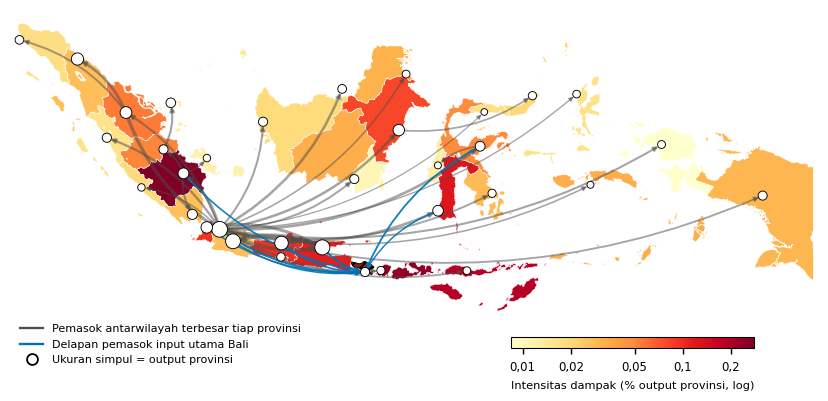

Gambar 11 tersimpan -> figur/4_4_11_jaringan_perdagangan_input.png | .pdf


In [ ]:
Zp = Z.reshape(N_PROV, N_SEK, N_PROV, N_SEK).sum(axis=(1, 3))   # Zp[r, s]: r memasok input ke s
np.fill_diagonal(Zp, 0)
beli_bali = Zp[:, IDX_BALI]

sisi_tulang = sorted({(int(np.argmax(Zp[:, j])), j) for j in range(N_PROV)})
sisi_tulang = [(i, j) for i, j in sisi_tulang if IDX_BALI not in (i, j)]
sisi_bali   = [(int(r), IDX_BALI) for r in np.argsort(beli_bali)[::-1][:8]]

fig, ax = plt.subplots(figsize=(LEBAR, 82 * MM), layout='constrained')
gdf[luar_g].plot(column='Intensitas', ax=ax, cmap='YlOrRd', norm=norm_i, edgecolor='white', lw=0.3)
gdf[~luar_g].plot(ax=ax, color=C_BALI, edgecolor='black', lw=0.5, hatch='////')
ax.set_xlim(*XLIM); ax.set_ylim(*YLIM); ax.set_aspect('equal'); ax.set_axis_off()
wmax = max(Zp[i, j] for i, j in sisi_tulang + sisi_bali)
pos = {i: (KOORD[p][1], KOORD[p][0]) for i, p in enumerate(PROV_NAMES)}
for (i, j), warna, z in [(e, '#4D4D4D', 2) for e in sisi_tulang] + [(e, C_SPILL, 4) for e in sisi_bali]:
    ax.add_patch(FancyArrowPatch(pos[i], pos[j], connectionstyle='arc3,rad=0.18', arrowstyle='-|>',
                                 mutation_scale=5, lw=0.3 + 2.4 * np.sqrt(Zp[i, j] / wmax),
                                 color=warna, alpha=0.5 if z == 2 else 0.9, zorder=z))
ax.scatter([pos[i][0] for i in range(N_PROV)], [pos[i][1] for i in range(N_PROV)],
           s=6 + 70 * np.sqrt(X_PROV / X_PROV.max()), color='white', edgecolor='black', lw=0.5, zorder=5)
cax = ax.inset_axes([0.62, 0.075, 0.30, 0.03])
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm_i, cmap='YlOrRd'), cax=cax, orientation='horizontal')
cb.set_label('Intensitas dampak (% output provinsi, log)', fontsize=6.3); atur_cbar_log(cb, norm_i.vmin, norm_i.vmax)
ax.legend(handles=[Line2D([], [], color='#4D4D4D', lw=1.3, label='Pemasok antarwilayah terbesar tiap provinsi'),
                   Line2D([], [], color=C_SPILL, lw=1.3, label='Delapan pemasok input utama Bali'),
                   Line2D([], [], marker='o', ls='', mfc='white', mec='black', label='Ukuran simpul = output provinsi')],
          loc='lower left', bbox_to_anchor=(0.0, 0.0), fontsize=6.2)

simpan(fig, '4_4_11_jaringan_perdagangan_input',
       'Jaringan perdagangan input antarprovinsi dan intensitas dampak',
       sumber=SUMBER_IRIO + ' Batas wilayah: BAKOSURTANAL 1:250.000.',
       catatan='Transaksi antara diagregasi ke tingkat provinsi; arah panah dari pemasok ke pembeli.')

### 7.3 Keterkaitan langsung dibandingkan spillover total

Porsi tiap provinsi dalam pembelian input antarwilayah Bali mencerminkan keterkaitan langsung. Porsinya dalam total spillover mencerminkan keterkaitan langsung ditambah seluruh putaran tidak langsung. Dari perbandingan keduanya:

- Provinsi di atas garis 45° **diperkuat**: menerima spillover melebihi peran langsungnya sebagai pemasok Bali, karena ikut terdampak lewat rantai pasok provinsi lain.
- Provinsi di bawah garis **teredam**.

Rasio $\log_2(\text{porsi spillover} / \text{porsi pembelian langsung})$ merangkum hal ini. Nilai 1 berarti porsinya dua kali lipat.

Spearman porsi pembelian langsung vs porsi spillover (N=33): rho = 0.955, p = 6.71e-18


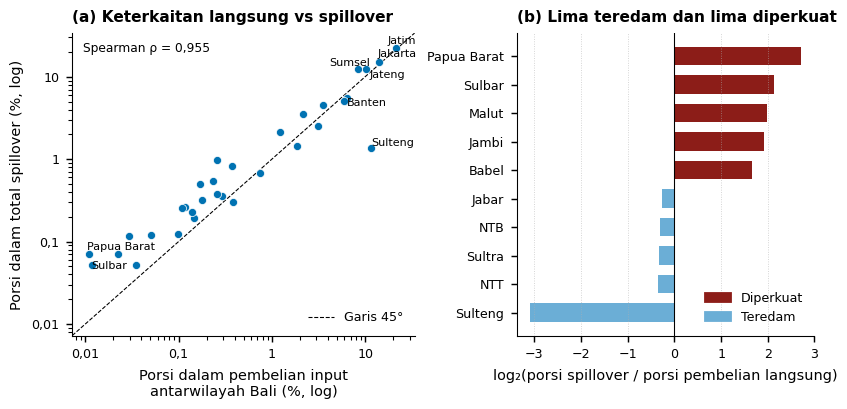

Gambar 12 tersimpan -> figur/4_4_12_langsung_vs_spillover.png | .pdf


In [ ]:
share_beli = beli_bali / beli_bali.sum() * 100
share_sp   = sp_abs / sp_abs.sum() * 100
rasio_amp  = share_sp / np.where(share_beli > 0, share_beli, np.nan)
rho_b, p_b = stats.spearmanr(share_beli[LUAR], share_sp[LUAR])
print(f'Spearman porsi pembelian langsung vs porsi spillover (N=33): rho = {rho_b:.3f}, p = {p_b:.3g}')

fig, axs = plt.subplots(1, 2, figsize=(LEBAR, 78 * MM), layout='constrained', width_ratios=[1.15, 1])
ax = axs[0]
ax.scatter(share_beli[LUAR], share_sp[LUAR], s=20, color=C_SPILL, edgecolor='white', lw=0.4, zorder=3)
nilai = np.r_[share_beli[LUAR], share_sp[LUAR]]
lo, hi = nilai[nilai > 0].min() / 1.5, nilai.max() * 1.5
ax.plot([lo, hi], [lo, hi], color='black', lw=0.6, ls='--', label='Garis 45°')
ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ekstrem = np.argsort(np.where(LUAR, np.abs(np.log(rasio_amp)), -np.inf))[::-1][:3]
pilih = set(df_edges['Target'].head(5)) | set(ekstrem)
teks = [ax.text(share_beli[i], share_sp[i], singkat(PROV_NAMES[i]), fontsize=6.2) for i in pilih]
adjust_text(teks, ax=ax, arrowprops=dict(arrowstyle='-', lw=0.4, color='#444444'))
ax.set_xlabel('Porsi dalam pembelian input\nantarwilayah Bali (%, log)')
ax.set_ylabel('Porsi dalam total spillover (%, log)')
ax.text(0.03, 0.97, f'Spearman ρ = {fmt(rho_b, 3)}', transform=ax.transAxes, va='top', fontsize=6.8)
ax.legend(loc='lower right')
ax.set_title('(a) Keterkaitan langsung vs spillover')

ax = axs[1]
d = pd.DataFrame({'p': PROV_NAMES, 'r': rasio_amp})[LUAR].dropna().sort_values('r')
d = pd.concat([d.head(5), d.tail(5)])
ax.barh(range(len(d)), np.log2(d['r']), color=np.where(d['r'] > 1, C_BALI, '#6BAED6'), height=0.65)
ax.axvline(0, color='black', lw=0.6)
ax.set_yticks(range(len(d))); ax.set_yticklabels([singkat(p) for p in d['p']])
ax.set_xlabel('log₂(porsi spillover / porsi pembelian langsung)')
ax.set_title('(b) Lima teredam dan lima diperkuat')
ax.legend(handles=[Patch(color=C_BALI, label='Diperkuat'), Patch(color='#6BAED6', label='Teredam')],
          loc='lower right')
ax.grid(axis='x', ls=':', lw=0.5, alpha=0.6)

simpan(fig, '4_4_12_langsung_vs_spillover',
       'Perbandingan keterkaitan langsung dengan Bali dan porsi spillover provinsi',
       catatan='Bali tidak diikutkan (N = 33).')

### 7.4 Berkas jaringan untuk Gephi

Tabel simpul dan sisi disimpan dalam format yang langsung dapat diimpor ke Gephi (Data Laboratory → Import Spreadsheet). Kolom `Group` membagi provinsi menurut median spillover 33 provinsi, dengan Bali tidak diikutkan dalam perhitungan median.

In [ ]:
median_sp = np.median(sp_abs[LUAR])
df_nodes = pd.DataFrame({
    'Id': range(N_PROV), 'Label': PROV_NAMES,
    'Dx_juta': dampak_prov.round(2), 'Dx_triliun': (dampak_prov / 1e6).round(5),
    'Intensitas_pct': intensitas.round(6), 'Is_Shock_Origin': (~LUAR).astype(int),
    'Koef_Struktural': koef_struktural.round(6),
    'Lat': [KOORD[p][0] for p in PROV_NAMES], 'Lon': [KOORD[p][1] for p in PROV_NAMES],
    'Group': np.where(~LUAR, 'Shock_Origin',
                      np.where(sp_abs >= median_sp, 'Spillover_di_atas_median', 'Spillover_di_bawah_median')),
    'Size': np.where(~LUAR, 100, 10 + 90 * np.sqrt(sp_abs / sp_abs.max())).round(1),
})
print(f'Simpul: {len(df_nodes)} | Sisi: {len(df_edges)}')
print(df_nodes['Group'].value_counts().to_string())

Simpul: 34 | Sisi: 33
Group
Spillover_di_atas_median     17
Spillover_di_bawah_median    16
Shock_Origin                  1


---
## Bagian 8 — Validasi

Pemeriksaan dibagi menjadi dua kelompok:

- **Syarat validitas** harus seluruhnya lolos. Jika satu saja gagal, hasil simulasi tidak dapat dipakai.
- **Karakteristik hasil** tidak wajib lolos. Kelompok ini memuat sifat hasil yang sesuai ekspektasi teoretis dan dilaporkan sebagai bahan pembahasan.

In [ ]:
hasil = []
def cek(kelompok, nama, kondisi, detail=''):
    hasil.append({'Kelompok': kelompok, 'Pemeriksaan': nama,
                  'Status': 'LOLOS' if kondisi else 'PERIKSA', 'Detail': detail})

V, K = 'Syarat validitas', 'Karakteristik hasil'
cek(V, 'Radius spektral A < 1', rho < 1, f'{rho:.4f}')
cek(V, 'Identitas baris Z·1 + f = x', sel_baris / x.max() < 1e-9, f'{sel_baris:.2e}')
cek(V, 'Invers Ghosh konsisten', np.abs(G - np.linalg.inv(np.eye(N_TOTAL) - B)).max() < 1e-6)
cek(V, 'Dimensi delta_f = 578', delta_f.shape == (N_TOTAL,), str(delta_f.shape))
cek(V, 'delta_f sama dengan berkas rincian', np.allclose(detail['DeltaFD_juta_Rp'].values, delta_f))
cek(V, 'Shock hanya di blok Bali', (luar_blok == 0).all(), f'{(luar_blok != 0).sum()} nilai di luar blok')
cek(V, 'Seluruh shock <= 0', (delta_f <= 0).all(), f'{(delta_f > 0).sum()} nilai positif')
cek(V, 'Shock tidak melebihi FD sektornya', n_tidak == 0, f'{n_tidak} sektor melebihi FD')
cek(V, 'Dekomposisi = total dampak', abs(sum(komponen.values()) - dx_nasional) < 1e-4,
    f'selisih {abs(sum(komponen.values()) - dx_nasional):.2e}')
cek(V, 'Jumlah dampak provinsi = nasional', abs(dampak_prov.sum() - dx_nasional) < 1e-4)
cek(V, 'Jumlah dampak sektor = nasional', abs(dampak_sek.sum() - dx_nasional) < 1e-4)

cek(K, 'Multiplier efektif > 1', mult_ef > 1, fmt(mult_ef, 4))
cek(K, 'Seluruh dampak bertanda negatif', (delta_x <= 1e-6).all(), f'{(delta_x > 1e-6).sum()} positif')
cek(K, 'Seluruh provinsi terdampak', (dampak_prov < 0).all(), f'{(dampak_prov >= 0).sum()} tidak terdampak')
cek(K, 'Dampak Bali > spillover', abs(dx_bali) > abs(dx_spillover),
    f'Bali {fmt(dx_bali / dx_nasional * 100, 1)}% vs spillover {fmt(dx_spillover / dx_nasional * 100, 1)}%')
cek(K, 'Efek umpan balik < 1% dampak Bali', abs(feedback_vec.sum()) < 0.01 * abs(dx_bali),
    f'{fmt(abs(feedback_vec.sum()) / abs(dx_bali) * 100, 3)}%')

df_valid = pd.DataFrame(hasil)
display(df_valid)
gagal = df_valid[(df_valid['Kelompok'] == V) & (df_valid['Status'] != 'LOLOS')]
assert gagal.empty, f'Syarat validitas gagal:\n{gagal}'
print('Seluruh syarat validitas terpenuhi.')

,Kelompok,Pemeriksaan,Status,Detail
0,Syarat validitas,Radius spektral A < 1,LOLOS,0.5947
1,Syarat validitas,Identitas baris Z·1 + f = x,LOLOS,9.54e-07
2,Syarat validitas,Invers Ghosh konsisten,LOLOS,
3,Syarat validitas,Dimensi delta_f = 578,LOLOS,"(578,)"
4,Syarat validitas,delta_f sama dengan berkas rincian,LOLOS,
5,Syarat validitas,Shock hanya di blok Bali,LOLOS,0 nilai di luar blok
6,Syarat validitas,Seluruh shock <= 0,LOLOS,0 nilai positif
7,Syarat validitas,Shock tidak melebihi FD sektornya,LOLOS,0 sektor melebihi FD
8,Syarat validitas,Dekomposisi = total dampak,LOLOS,selisih 0.00e+00
9,Syarat validitas,Jumlah dampak provinsi = nasional,LOLOS,


Seluruh syarat validitas terpenuhi.


---
## Bagian 9 — Ekspor

Nama berkas A1–E1 dipertahankan dari versi sebelumnya. Berkas yang baru ditambahkan di versi ini adalah B2, A3, A4, dan F0.

| Berkas | Isi | Dipakai di |
|---|---|---|
| A1_Dampak_per_Provinsi | Δx, intensitas, koefisien struktural per provinsi | 4.4 |
| A2_Dampak_per_Sektor | Δx per sektor (Bali dan nasional) | 4.4 |
| A3_Spillover_per_Sektor | Spillover per sektor di luar Bali | 4.4 |
| A4_Matriks_Provinsi_Sektor | Δx provinsi × sektor (miliar Rp) | 4.4 |
| B1_Linkage_BL_FL | Multiplier, BL, FL, klasifikasi | 4.4 |
| B2_Dekomposisi_Dampak | Dekomposisi total dan per sektor Bali | 4.4 |
| B3_Dampak_PDRB | Dampak terhadap nilai tambah / PDRB | 4.4 |
| C1_Spillover_Interregional | Spillover dan koefisien struktural | Tujuan 3 |
| C2/C3_network_nodes/edges | Jaringan untuk Gephi | 4.4 |
| D1/D2 | Uji kelayakan shock dan validasi | Lampiran |
| E1_Input_Analisis_Spasial | Masukan Moran's I dan LISA | Tujuan 3 |
| F0_Daftar_Gambar | Judul, sumber, dan catatan setiap gambar | Naskah |

In [ ]:
df_sek = pd.DataFrame({
    'Kode_S': KODE_S, 'KBLI': KBLI, 'Sektor': SEKTOR_17,
    'Shock_langsung_T': (-df_b / 1e6).round(4),
    'Dx_Bali_T': (DX[IDX_BALI] / 1e6).round(4),
    'Dx_Luar_Bali_T': (spill_sek / 1e6).round(4),
    'Dx_Nasional_T': (dampak_sek / 1e6).round(4),
    'Pct_nasional': (dampak_sek / dx_nasional * 100).round(3),
})

df_sp = df_prov[LUAR][['IDX', 'Provinsi', 'Dx_juta', 'Dx_triliun', 'Koef_Struktural_L']].rename(
    columns={'Dx_juta': 'Spillover_juta', 'Dx_triliun': 'Spillover_triliun'})
df_sp['Spillover_triliun'] = (df_sp['Spillover_juta'] / 1e6).round(5)
df_sp['Pct_total_spillover'] = (df_sp['Spillover_juta'] / dx_spillover * 100).round(3)
df_sp = df_sp.sort_values('Spillover_juta').reset_index(drop=True)

df_tujuan3 = df_prov[['Provinsi', 'Dx_juta', 'Dx_triliun', 'Lat', 'Lon', 'Tipe']].merge(
    df_sp[['Provinsi', 'Koef_Struktural_L', 'Spillover_triliun']], on='Provinsi', how='left')
df_tujuan3[['Koef_Struktural_L', 'Spillover_triliun']] = df_tujuan3[['Koef_Struktural_L', 'Spillover_triliun']].fillna(0)

df_gambar = pd.DataFrame(DAFTAR_GAMBAR)

berkas = {
    'A1_Dampak_per_Provinsi.csv'      : df_prov,
    'A2_Dampak_per_Sektor.csv'        : df_sek,
    'A3_Spillover_per_Sektor.csv'     : df_spill_sek,
    'A4_Matriks_Provinsi_Sektor.csv'  : df_matriks.round(4).reset_index(names='Provinsi'),
    'B1_Linkage_BL_FL.csv'            : df_link,
    'B2_Dekomposisi_Dampak.csv'       : df_dekom,
    'B3_Dampak_PDRB.csv'              : df_pdrb.reset_index(),
    'B2b_Dekomposisi_per_Sektor_Bali.csv': df_dekom_sek,
    'C1_Spillover_Interregional.csv'  : df_sp,
    'C2_network_nodes.csv'            : df_nodes,
    'C3_network_edges.csv'            : df_edges,
    'D1_Uji_Kelayakan_Shock.csv'      : df_uji,
    'D2_Validasi.csv'                 : df_valid,
    'E1_Input_Analisis_Spasial.csv'   : df_tujuan3,
    'F0_Daftar_Gambar.csv'            : df_gambar,
}
for nama, d in berkas.items():
    d.to_csv(CSV_OUT_DIR + nama, index=False, encoding='utf-8-sig')

np.save(NPY_OUT_DIR + 'delta_x.npy', delta_x)
np.save(NPY_OUT_DIR + 'x_rekonstruksi.npy', x)

with pd.ExcelWriter(XLSX_OUT_DIR + 'Ringkasan_IRIO_Simulator_Bali.xlsx', engine='openpyxl') as w:
    for sheet, d in [('Dampak_Provinsi', df_prov), ('Dampak_Sektor', df_sek), ('Spillover_Sektor', df_spill_sek),
                     ('Linkage', df_link), ('Dekomposisi', df_dekom), ('Dekomposisi_Sektor', df_dekom_sek), ('Dampak_PDRB', df_pdrb.reset_index()),
                     ('Spillover', df_sp), ('Uji_Kelayakan', df_uji), ('Validasi', df_valid),
                     ('Input_Spasial', df_tujuan3), ('Daftar_Gambar', df_gambar)]:
        d.to_excel(w, sheet_name=sheet, index=False)

arsip = '/content/hasil_irio_simulator.zip' if os.path.isdir('/content') else OUT_DIR + 'hasil_irio_simulator.zip'
with zipfile.ZipFile(arsip, 'w', zipfile.ZIP_DEFLATED) as zf:
    for sub in [CSV_OUT_DIR, NPY_OUT_DIR, XLSX_OUT_DIR, FIG_DIR]:
        for f in os.listdir(sub):
            zf.write(sub + f, os.path.relpath(sub + f, OUT_DIR))

print(f'{len(berkas)} CSV, 2 NPY, 1 XLSX, {len(DAFTAR_GAMBAR)} gambar tersimpan.')
print(f'Arsip: {arsip} ({os.path.getsize(arsip) / 1e6:,.1f} MB)')
print('Untuk mengunduh di Colab: from google.colab import files; files.download(arsip)')

15 CSV, 2 NPY, 1 XLSX, 12 gambar tersimpan.
Arsip: /content/hasil_irio_simulator.zip (4.6 MB)
Untuk mengunduh di Colab: from google.colab import files; files.download(arsip)


### 9.1 Daftar gambar dan ringkasan untuk naskah

Tabel pertama berisi keterangan gambar untuk disalin ke Word. Nomor gambar disesuaikan dengan penomoran di naskah. Tabel kedua merangkum angka kunci yang dirujuk di teks subbab 4.4.

In [ ]:
display(df_gambar[['No', 'Berkas', 'Judul', 'Catatan']])

top5 = df_sp.head(5)
ringkas = pd.DataFrame({'Indikator': [
    'Shock permintaan akhir', 'Dampak output nasional', 'Dampak di Bali', '  - efek langsung',
    '  - efek tidak langsung intraregional', '  - efek umpan balik', 'Spillover ke luar Bali',
    'Multiplier efektif', 'Dampak PDRB nasional', 'Sektor kunci Bali', 'Porsi kebocoran multiplier rata-rata',
    'Sektor saluran spillover terbesar', 'Lima provinsi penerima terbesar', 'Provinsi intensitas tertinggi',
], 'Nilai': [
    f'Rp{fmt(-total_shock / 1e6)} T ({(df_b != 0).sum()} sektor)',
    f'Rp{fmt(-dx_nasional / 1e6)} T',
    f'Rp{fmt(-dx_bali / 1e6)} T ({fmt(dx_bali / dx_nasional * 100, 1)}%)',
    f'Rp{fmt(-komponen["Efek langsung"] / 1e6)} T',
    f'Rp{fmt(-komponen["Efek tidak langsung intraregional"] / 1e6)} T',
    f'Rp{fmt(-komponen["Efek umpan balik (feedback)"] / 1e6, 4)} T',
    f'Rp{fmt(-dx_spillover / 1e6)} T ({fmt(dx_spillover / dx_nasional * 100, 1)}%)',
    fmt(mult_ef, 4),
    f'Rp{fmt(-dv_nasional / 1e6)} T (multiplier {fmt(dv_nasional / delta_f.sum(), 4)})',
    ', '.join(df_link.loc[df_link['Klasifikasi'] == 'Sektor kunci', 'Sektor_singkat']) or '-',
    f'{fmt((mult_inter / mult_total).mean() * 100, 1)}%',
    f'{df_spill_sek.iloc[0]["Sektor_singkat"]} ({fmt(df_spill_sek.iloc[0]["Porsi_spillover_pct"], 1)}%)',
    ', '.join(f'{p} ({fmt(s, 1)}%)' for p, s in zip(top5['Provinsi'], top5['Pct_total_spillover'])),
    luar.sort_values('Intensitas_pct', ascending=False).iloc[0]['Provinsi'],
]})
display(ringkas.set_index('Indikator'))
print("\nLangkah berikutnya: E1_Input_Analisis_Spasial.csv -> notebook Tujuan 3 (Moran's I dan LISA).")

,No,Berkas,Judul,Catatan
0,1,4_4_01_klasifikasi_sektor_bali,Klasifikasi sektor Bali berdasarkan backward d...,"BL dari invers Leontief, FL dari invers Ghosh;..."
1,2,4_4_02_multiplier_intra_inter,Multiplier output sektor Bali menurut wilayah ...,Angka di ujung batang = porsi multiplier yang ...
2,3,4_4_03_shock_permintaan_akhir,Shock permintaan akhir per sektor di Provinsi ...,Persentase = proporsi shock terhadap permintaa...
3,4,4_4_04_dekomposisi_dampak,Dekomposisi dampak shock pariwisata Bali terha...,Angka dalam kurung = porsi terhadap dampak nas...
4,5,4_4_05_peringkat_provinsi,Lima belas provinsi penerima spillover terbesa...,Bali tidak ditampilkan. Intensitas = |Δx| terh...
5,6,4_4_06_peta_intensitas,Intensitas dampak shock pariwisata Bali terhad...,Label menunjukkan enam provinsi dengan intensi...
6,7,4_4_07_dampak_sektor_bali,Dampak shock terhadap output sektor di Provins...,Tanda * = sektor lingkup pariwisata (menerima ...
7,8,4_4_08_spillover_sektor,Spillover dampak ke luar Bali menurut sektor,Angka dalam kurung = porsi terhadap total spil...
8,9,4_4_09_matriks_provinsi_sektor,Sebaran spillover menurut provinsi dan sektor,"Sepuluh provinsi penerima spillover terbesar, ..."
9,10,4_4_10_peta_aliran_spillover,Aliran spillover dari Bali ke 11 provinsi pene...,"Panah yang digambar menutup 90,7% total spillo..."


,Nilai
Indikator,
Shock permintaan akhir,"Rp84,39 T (10 sektor)"
Dampak output nasional,"Rp142,65 T"
Dampak di Bali,"Rp112,43 T (78,8%)"
- efek langsung,"Rp84,39 T"
- efek tidak langsung intraregional,"Rp28,01 T"
- efek umpan balik,"Rp0,0234 T"
Spillover ke luar Bali,"Rp30,22 T (21,2%)"
Multiplier efektif,"1,6903"
Dampak PDRB nasional,"Rp81,10 T (multiplier 0,9610)"



Langkah berikutnya: E1_Input_Analisis_Spasial.csv -> notebook Tujuan 3 (Moran's I dan LISA).
